# Do Comics Mirror America?
### Women at work in Marvel and DC characters vs. the real U.S. workforce, 1940 to 2025
**Team:** A07

**Members:** Daniel Igbokwe, Carly Barry, Eliza Bashirian, Albert Dorofeev, Emanuele Borroni

**Project Manager:** Albert Dorofeev

# Executive Summary

**Objective.** Measure whether Marvel and DC characters reflect the move of American women into paid work, and how far behind society the two publishers are.

**Key findings**
1. **Comics best match the workforce of about 7 years earlier.** The female share of new characters moves with women’s labor force participation (r = 0.83), and the match is best against the workforce of 7 years earlier (r = 0.89). This suggests a lag, but does not prove that comics react to society.
2. **The roster is still about 70% male, but new characters changed fast.** The female share of new characters rose from 11.5% in 1960 to 40.0% in 2025.
3. **Female characters get "women's jobs".** Their job groups are on average 50.1% female in the real workforce, against 42.9% for male characters. In historically male-dominated jobs, female characters reached 20% only in the 2010s; real women did in the 1980s.
4. **Women are written with fewer working lives.** 57.1% of female characters have an occupation listed, against 66.7% of male characters.

**Recommendations for the editorial team**
- Benchmark the gender mix of new characters against current workforce data every year, instead of matching where society was years earlier.
- Cast new female characters in managerial, professional and other historically male roles, where comics trail reality by decades.
- Give every new character a civilian occupation, so characters, male and female, read as people with working lives.

# Problem Definition

Since the 1940s, American women have moved into paid work and into jobs that were once open only to men. This project aims to analyze whether Marvel and DC reflected that change, led it, or lagged behind it, by comparing the jobs that comic book characters hold with the jobs that real American women held at the same time. The stakeholder is an editorial team at a major publisher deciding how to write and cast new characters. Even though they state publicly that their characters should reflect their audience, they have no measure of how far their characters actually sit from the society they depict. This project's success lies in our ability to show, with specific numbers, where comic book characters' occupations match and where they do not match real employment patterns among American women: giving editorial a concrete baseline instead of an impression.

# Introduction and Motivation

Comics are one of America’s oldest mass media, and Marvel and DC characters now reach far beyond the page through film, TV and games. Representation in comics is a recurring public debate. Since the 1940s, the share of American women in paid work rose from about one in three to about six in ten, and women entered many jobs once closed to them.

If comics truly mirror America, that change should show up in who gets created and what jobs they are given. This notebook tests that claim with numbers instead of impressions. Anyone who works on character creation, casting or brand strategy will learn where comics match reality, where they lag, and by how much.

# Summary of the Team Assignment

The Team Assignment built the dataset and answered the first descriptive questions. In short:

- **Scraped and cleaned two messy wiki tables.** Gender had 83 raw values (typos, editor notes, identities that changed over time), grouped into Male, Female, Other and Unknown. Occupation was free text with wiki markup; we kept each character's first current job and sorted about 15,000 distinct values into census job groups plus comic-only groups.
- **Removed DC reboot duplicates.** DC's reboots give one character several pages (Barbara Gordon has 4). Keeping each character's earliest version removed 1,953 duplicate rows and a false wave of new characters in the 2010s.
- **Built two joins.** Characters to U.S. jobs on job group and decade, and the yearly female share of new characters to women's labor force participation on year.
- **Baseline findings (Q1 to Q3, Q5, Q6).** Both rosters are about 70% male; most characters debuted after 1960; female characters debuted about 7 years later than male ones; and the female share of new characters rose with women's labor force participation, matching the workforce of 5 to 10 years earlier best.

The **final project** goes further on three new questions: exactly how long comics lag and whether Marvel and DC differ (Q7, Q8); whether female characters are steered into stereotypically female jobs and whether that changed (Q9 to Q14); and whether women are written with working lives at all (Q15, Q16).

# Data Sources and Data Dictionary

| Table | Source | Collection | Size (raw) |
|---|---|---|---|
| Marvel characters | [Marvel Database](https://marvel.fandom.com/wiki/Category:Earth-616/Characters) (Fandom wiki) | Full API scrape of Earth-616, 29 Sep 2026 | 37,204 rows x 25 columns |
| DC characters | [DC Database](https://dc.fandom.com/wiki/DC_Comics_Database) (Fandom wiki) | Full API scrape of Earth-Two, Earth-One, New Earth and Prime Earth, 29 Sep 2026 | 14,671 rows x 26 columns |
| U.S. jobs by sex | [IPUMS USA](https://usa.ipums.org/usa/), University of Minnesota | Census 1940 to 2000 and ACS 2001 to 2023, tabulated by occupation (OCC1950) and sex in IPUMS Abacus | 5,772 rows x 12 columns |
| Women's labor force participation | [BLS series LNS11300002 via FRED](https://fred.stlouisfed.org/series/LNS11300002) | Monthly participation rate of women 16+, 1948 to Aug 2026 | 944 rows x 2 columns |

**Data and method.** We scraped every character page from the Marvel and DC Fandom wikis (49,922 characters after cleaning) and joined them to real U.S. data: women’s share of each census job group by decade (IPUMS USA, 1940 to 2023) and women’s labor force participation by year (BLS via FRED, 1948 to 2026). About 15,000 free-text occupations were sorted into the same census job groups, so characters and real workers can be compared directly.

**License and terms.** Fandom content is CC BY-SA 3.0. IPUMS USA data is free for academic use under the IPUMS terms and may not be redistributed. FRED/BLS data is public domain.

**Access.** The raw CSVs are in the team's Google Drive folder [000-Project/Datasets](https://drive.google.com/drive/u/1/folders/1Ic78oG2q45n7K29xUW3PxeXoteddSB_I). Add a shortcut to it in My Drive and run the notebook; it finds the folder automatically.

### Data dictionaries (raw data sets)

**Table 1: Marvel characters** (`marvel_characters_raw.csv`, 37,204 rows x 25 columns, one row per wiki page)

| Column | Type | Description | Used |
|---|---|---|---|
| `page_id` | integer | Unique ID of the character's wiki page | No |
| `page_title` | text | Title of the wiki page, e.g. "Peter Parker (Earth-616)" | Yes |
| `publisher` | text | Publisher of the character (Marvel) | Yes |
| `name` | text | The character's real or civilian name | No |
| `current_alias` | text | Codename or hero/villain name the character currently uses | No |
| `universe` | text | Fictional universe or reality the character comes from | No |
| `gender` | text | Gender as written on the page (free text with typos and editor notes) | Yes |
| `identity` | text | Whether the identity is secret, public or unknown | No |
| `citizenship` | text | Country or nation the character is a citizen of | No |
| `marital_status` | text | Relationship status, such as single, married or widowed | No |
| `occupation` | text | The character's jobs, as free text with wiki markup | Yes |
| `education` | text | Schooling or training background | No |
| `origin` | text | How the character got their powers or what kind of being they are | No |
| `place_of_birth` | text | Where the character was born | No |
| `base_of_operations` | text | Main location the character works from | No |
| `creators` | text | Writers and artists who created the character | No |
| `first_appearance` | text | Comic issue of the character's first appearance | No |
| `death` | text | Whether and how the character has died | No |
| `debut_year_category` | text | Debut year from the wiki's category tags; some cells hold two years, e.g. "1963;1981" | Yes |
| `sexuality_gender_categories` | text | Wiki categories on sexuality and gender identity | No |
| `has_character_template` | boolean | Whether the page uses the wiki's standard character template | No |
| `notices_before_template` | text | Editor notices placed before the template | No |
| `revision_id` | integer | ID of the page revision that was scraped | No |
| `last_edited` | text | Date the page was last edited | No |
| `scraped_on` | text | Date we scraped the page (29 Sep 2026) | No |

**Table 2: DC characters** (`dc_characters_raw.csv`, 14,671 rows x 26 columns, one row per wiki page)

Same structure as Marvel, with these differences:

| Column | Type | Description | Used |
|---|---|---|---|
| `real_name` | text | The character's real or civilian name (Marvel: `name`) | No |
| `main_alias` | text | Main codename (Marvel: `current_alias`) | No |
| `alignment` | text | Good, bad or neutral | No |
| `education` | number | Empty for every DC character | No |
| `last_appearance` | text | Comic issue of the character's last appearance | No |
| `continuity_categories` | text | DC continuity the page belongs to (Earth-One, Earth-Two, New Earth, Prime Earth) | No |

DC has no `origin` or `place_of_birth` columns. `page_title` carries the continuity in brackets, e.g. "Barbara Gordon (New Earth)", which we used to remove reboot duplicates.

**Table 3: U.S. jobs by sex** (`us_jobs_by_sex_ipums_1940_2023.csv`, 5,772 rows x 12 columns, one row per occupation and year)

| Column | Type | Description | Used |
|---|---|---|---|
| `year` | integer | Census year (1940 to 2000) or ACS year (2001 to 2023) | Yes |
| `sample` | text | IPUMS sample the row comes from (Census or ACS) | No |
| `occ1950_code` | integer | Occupation code in the 1950 Census classification, consistent across years | Yes |
| `occupation` | text | Occupation name for that code | No |
| `is_occupation` | boolean | False for codes 997 and 999, which are not real occupations | Yes |
| `men_employed` | integer | Estimated number of employed men (weighted) | No |
| `women_employed` | integer | Estimated number of employed women (weighted) | Yes |
| `total_employed` | integer | Estimated total employed (men plus women) | Yes |
| `pct_women` | number | Women's share of the occupation (%); missing for the one row with 0 workers | No |
| `men_sample_cases` | integer | Number of men in the survey sample behind the estimate | No |
| `women_sample_cases` | integer | Number of women in the survey sample behind the estimate | No |
| `low_sample_flag` | boolean | True when the sample is small, so the share is less reliable | Yes |

**Table 4: Women's labor force participation** (`FRED_LNS11300002_women_lfpr.csv`, 944 rows x 2 columns, one row per month)

| Column | Type | Description | Used |
|---|---|---|---|
| `observation_date` | text | First day of the month, Jan 1948 to Aug 2026 | Yes |
| `LNS11300002` | number | Share of women aged 16+ in the labor force (%), seasonally adjusted; missing for Oct 2025 | Yes |


### Data dictionary (final analysis tables)

**`comics`**: one row per character, Marvel and DC stacked (49,922 rows)

| Column | Type | Meaning |
|---|---|---|
| `character` | text | Character name, with the universe suffix removed |
| `publisher` | text | Marvel or DC |
| `gender` | text | Male, Female, Other (agender, non-binary, genderfluid, ...) or Unknown |
| `debut_year` | number | Year of first appearance (earliest year if the wiki lists two) |
| `debut_decade` | number | `debut_year` rounded down to the decade |
| `main_job` | text | First current occupation listed on the wiki page, wiki markup removed |
| `occ_group` | text | `main_job` sorted into the 11 census job groups, 7 comic-only groups (Criminal, Hero/Adventurer, Military, Spy/Agent, Royalty/Mystic, Student, Not working), Other, or Unknown (no occupation listed) |

**`comics_jobs`**: `comics` plus `us_pct_women`, the share of real U.S. workers in the character's job group who were women in the character's debut decade (empty for comic-only groups and pre-1940 debuts).

**`jobs_by_group`**: one row per decade and census job group: `decade`, `occ_group`, `women_employed`, `total_employed`, `us_pct_women`.

**`comics_fred`**: one row per year, 1948 to 2026: `year`, `pct_female` (female share of new characters with known gender), `women_lfpr_pct` (yearly average participation rate, %), `months` (months of FRED data in that year).

**Definition used throughout:** "female share" is computed among characters with a known gender (Unknown excluded), except in Q1, which shows the full split.

# Setup

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 30)

PUB_COLORS    = {"Marvel": "#ec1d24", "DC": "#0476f2"}
GENDER_COLORS = {"Female": "#c90076", "Male": "#2986cc"}
SOURCE_COLORS = {"Comics": "#f6db35", "US workforce": "#fc6600"}

def finish_chart(ax, title, xlabel, ylabel, legend_title=None, grid="y"):
    """Team standard: bold title, labeled axes, light grid, legend without frame. Call it LAST."""
    ax.set_title(title, fontsize=13, weight="bold", loc="left")
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.grid(axis=grid, alpha=0.3)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)
    if legend_title is not None:
        ax.legend(title=legend_title or None, frameon=False)
    plt.tight_layout()
    plt.show()

## Load the data

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CANDIDATES = [
        "/content/drive/MyDrive/000-Project/Datasets",
        "/content/drive/MyDrive/BU MSBA COURSES/BA 780 (Introduction to Data Analytics)/000-Project/Datasets",
    ]
except ImportError:
    CANDIDATES = ["data"]

DATA_DIR = next((p for p in CANDIDATES if os.path.isdir(p)), None)
assert DATA_DIR, "Data folder not found. Add the 000-Project shortcut to My Drive."

marvel_raw = pd.read_csv(f"{DATA_DIR}/marvel_characters_raw.csv")
dc_raw     = pd.read_csv(f"{DATA_DIR}/dc_characters_raw.csv")
jobs_raw   = pd.read_csv(f"{DATA_DIR}/us_jobs_by_sex_ipums_1940_2023.csv")
fred_raw   = pd.read_csv(f"{DATA_DIR}/FRED_LNS11300002_women_lfpr.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## First look
One summary table for all four raw tables, then the first rows of each.

In [ ]:
raw_tables = {"Marvel": marvel_raw, "DC": dc_raw, "US jobs (IPUMS)": jobs_raw, "FRED": fred_raw}

overview = pd.DataFrame({
    name: {"rows": len(df),
           "columns": df.shape[1],
           "duplicate rows": df.duplicated().sum(),
           "missing cells (%)": round(df.isna().mean().mean() * 100, 1),
           "columns over 50% empty": (df.isna().mean() > 0.5).sum()}
    for name, df in raw_tables.items()
}).T
display(overview)

for name, df in raw_tables.items():
    print(name)
    display(df.head(3))

,rows,columns,duplicate rows,missing cells (%),columns over 50% empty
Marvel,37204.0,25.0,0.0,29.2,7.0
DC,14671.0,26.0,0.0,25.8,5.0
US jobs (IPUMS),5772.0,12.0,0.0,0.0,0.0
FRED,944.0,2.0,0.0,0.1,0.0


Marvel


,page_id,page_title,publisher,name,current_alias,universe,gender,identity,citizenship,marital_status,occupation,education,origin,place_of_birth,base_of_operations,creators,first_appearance,death,debut_year_category,sexuality_gender_categories,has_character_template,notices_before_template,revision_id,last_edited,scraped_on
0,1934796,"""Another Super Hero"" (Earth-616)",Marvel,NaN,"""Another Super Hero""",Earth-616,Male,Secret,American,NaN,Adventurer,NaN,[[Humans (Homo sapiens)|Human]] [[Glossary:Mut...,NaN,"[[New York City]], [[New York (State)|New York...",Marie Severin,Marvel Mini-Book: Amazing Spider-Man Vol 1 1,NaN,1966,NaN,True,NaN,11003049,2026-06-18T10:20:02Z,2026-09-29
1,322600,'Spinner (Earth-616),Marvel,'Spinner,NaN,Earth-616,Male,Secret,NaN,Single,NaN,NaN,[[Alien]],NaN,Mobile,Stuart Moore; Clayton Henry,Marvel Comics Presents Vol 2 1,NaN,2007,NaN,True,NaN,10458542,2025-10-06T02:19:08Z,2026-09-29
2,1672300,0-XXII (Earth-616),Marvel,0-XXII,NaN,Earth-616,NaN,No Dual,NaN,NaN,NaN,NaN,[[Eternals (Homo immortalis)|Eternal]],NaN,NaN,Kieron Gillen,Eternals Vol 5 1,NaN,2021,NaN,True,NaN,11121099,2026-08-15T11:27:52Z,2026-09-29


DC


,page_id,page_title,publisher,real_name,main_alias,universe,gender,alignment,identity,citizenship,marital_status,occupation,education,base_of_operations,creators,first_appearance,last_appearance,death,debut_year_category,sexuality_gender_categories,continuity_categories,has_character_template,notices_before_template,revision_id,last_edited,scraped_on
0,338810,2-6-8-1-7-9-5 (Prime Earth),DC,2-6-8-1-7-9-5,Two-Six,Prime Earth,Female,Good,Public,NaN,Single,[[Green Lantern]],NaN,NaN,Robert Venditti; Billy Tan,Green Lantern Vol 5 21,NaN,NaN,2013,NaN,Prime Earth Characters,True,NaN,3884659,2026-04-06T22:58:21Z,2026-09-29
1,193622,3g4 (New Earth),DC,3g4,3g4,Fourth World; New Earth,Male,Good,NaN,Apokoliptian,NaN,NaN,NaN,[[Apokolips]],Peter David; Jim Calafiore;,Aquaman Vol 5 #37,NaN,Aquaman Vol 5 #37,1997,NaN,New Earth Characters,True,NaN,3885116,2026-04-07T14:44:31Z,2026-09-29
2,529691,50% Chad (Prime Earth),DC,Unknown,50% Chad,Prime Earth,Male,Bad,Secret,NaN,Single,NaN,NaN,NaN,Gerard Way; Nick Derington,Doom Patrol Vol 6 9,NaN,NaN,2018,NaN,Prime Earth Characters,True,NaN,3776428,2025-06-04T13:53:21Z,2026-09-29


US jobs (IPUMS)


,year,sample,occ1950_code,occupation,is_occupation,men_employed,women_employed,total_employed,pct_women,men_sample_cases,women_sample_cases,low_sample_flag
0,1940,1940 census 1%,1,Actors and actresses,True,8600,4700,13300,35.34,86,58,False
1,1940,1940 census 1%,2,Airplane pilots and navigators,True,7200,300,7500,4.00,65,3,False
2,1940,1940 census 1%,3,Architects,True,18800,600,19400,3.09,189,3,False


FRED


,observation_date,LNS11300002
0,1948-01-01,32.0
1,1948-02-01,32.4
2,1948-03-01,32.1


**Takeaway:** no duplicate rows in any table. The two character tables have several near-empty columns (education is empty for every DC character) and their text fields still contain wiki markup. The jobs table has codes 997/999 that are not real occupations, and FRED is missing October 2025 (government shutdown).

# Data Cleaning

Every table is cleaned on a copy, so the raw data stays untouched. Missing values are labeled `Unknown` instead of dropped.

| Field | Problem | Rule |
|---|---|---|
| Gender | 83 raw values: typos (`Femle`, `Mal`), editor notes, changing identities | Group into Male / Female / Other / Unknown; use the current gender if several are listed |
| Debut year | Text, some cells hold two years (`1963;1981`) | Keep the first (earliest) year; add `debut_decade` |
| Occupation | 11,145 (Marvel) and 3,869 (DC) free-text values with bullets, links, citations, a "Formerly" section | Remove markup, keep the first current job, sort it into a job group by keyword (first match wins) |
| DC pages | Reboots give one character several pages | Keep each character's earliest version |
| US jobs | Codes 997/999 are not occupations; one row has 0 workers | Drop them; group OCC1950 codes into the 11 census job groups |
| FRED | Monthly data | Average to yearly, keep a count of months |

## Cleaning functions

In [ ]:
# Gender -> Male / Female / Other / Unknown
other_words = ["agender", "agenger", "non-binary", "genderfluid", "transgender", "variable", "gestalt",
               "genderless", "intersex", "/"]   # '/' is for 'Male/Female'

def clean_gender(g):
    if pd.isna(g):
        return "Unknown"
    g = g.lower()
    g = g.split("<!--")[0]      # remove the editor notes, if the cell was only a note we're left with ''
    g = g.split("{{")[0]        # remove citations

    # mixed ones: the current gender is listed first, e.g. 'female (currently); male (formerly)'
    parts = g.split(";")
    g = parts[0]
    # except a few that list the original one first -> use the second part
    if "original" in g and len(parts) > 1:
        g = parts[1]

    g = g.strip()
    for word in other_words:
        if word in g:
            return "Other"
    if g.startswith("female") or g.startswith("femle") or g.startswith("emale"):   # check female before male!
        return "Female"
    if g.startswith("mal"):     # Male, Mal, Maleno
        return "Male"
    return "Unknown"            # '', 'unknown', and anything we can't tell


# Occupation text -> main current job
def remove_between(text, start_mark, end_mark):
    """Remove everything from start_mark to end_mark, e.g. '<!-- note -->' or '{{r|...}}'"""
    while start_mark in text:
        start = text.find(start_mark)
        end = text.find(end_mark, start)
        if end == -1:                 # never closed -> cut off the rest
            return text[:start]
        text = text[:start] + text[end + len(end_mark):]
    return text

def get_main_job(text):
    if pd.isna(text):
        return np.nan
    text = text.lower()

    # remove the wiki stuff: editor notes, citations/templates, category tags, html tags (<br> = new line)
    text = remove_between(text, "<!--", "-->")
    text = remove_between(text, "{{", "}}")
    text = remove_between(text, "[[category", "]]")
    text = text.replace("<br />", ",").replace("<br/>", ",").replace("<br>", ",")
    text = remove_between(text, "<", ">")
    text = text.replace("''", "").replace("*", "")

    # links look like [[page name|text shown]] -> keep just the text shown
    pieces = text.split("[[")
    for i in range(1, len(pieces)):
        link = pieces[i].split("]]")[0]
        if "|" in link:
            pieces[i] = pieces[i].replace(link, link.split("|")[1])
    text = "".join(pieces).replace("]]", "")

    # cut off the old jobs - only use them if there's nothing current listed
    before = text.split("formerly")[0]
    if before.strip(" \n:,;") == "" and "formerly" in text:
        text = text.split("formerly")[1]
    else:
        text = before

    # jobs are separated by new lines, commas, ; or /  -> make them all commas and split
    text = text.replace("\n", ",").replace(";", ",").replace("/", ",").replace(" and ", ",")
    jobs = text.split(",")

    for job in jobs:
        job = job.strip(" .:-()")
        if job == "" or job.startswith("former"):   # skip blanks and old jobs like 'former boxer'
            continue
        return job

    # only old jobs listed -> use the first one
    for job in jobs:
        job = job.strip(" .:-()")
        if job != "":
            return job.replace("former ", "")
    return np.nan


occ_keywords = [
    ("Criminal", ["criminal", "crime", "thief", "thiev", "robber", "burglar", "gangster", "mobster", " mob ", " gang", "assassin", "terroris", "smuggl", "drug", "racketeer", "outlaw", "pirate", "henchm", "hitman", "hit man", "killer", "murder", "bandit", "kidnap", "con artist", "con man", "swindler", "forger", "saboteur", "arms dealer", "poacher", "enforcer", "thug", "extort", "bootleg", "bounty hunter", "mercenar", "villain", "conqueror", " cult", "counterfeit", " fence ", "pickpocket", "crook", "safecracker", "arsonist", "grifter", "pimp", "fugitive", "raider", "invader", "minion", "anarchist", "subversive", "warmonger", "despot", "infiltrator", "black market", "rustler", "slaver"]),
    ("Hero/Adventurer", ["adventurer", "superhero", "super hero", "vigilante", "crimefighter", "crime fighter", "crime-fighter", " hero", "avenger", "defender", "freedom fighter", "guardian", "protector", "crusader", "x-men", "x-man", "explorer", "lantern", "sidekick", "side-kick", "spirit of vengeance", "demon hunter", "vampire hunter", "monster hunter", "witch hunter", "mutant hunter", "manhunter", "time traveler"]),
    ("Service", ["police", "sheriff", "detective"]),
    ("Sales", ["real estate", "insurance agent", "talent agent", "travel agent"]),
    ("Managers/Officials", ["civil servant", "public servant"]),
    ("Military", ["soldier", "army", "military", "marine", "general ", "colonel", "sergeant", "lieutenant", " major ", "admiral", " navy", "naval", "commando", "warrior", "knight", "gladiator", "samurai", "ninja", "warlord", "troop", "infantry", "militia", "centurion", "legionnaire", "guardsman", "captain", "spaceknight", "air force", "fighter pilot", "rebel", "revolutionar", "guerrilla", " war ", "commander", "resistance fighter", " scout", "corpsman", "peacekeeper", "sentry", "musketeer", " archer", "praetor", "valkyrie", "black ops"]),
    ("Spy/Agent", [" spy", "espionage", "agent", "s.h.i.e.l.d", "operative", "intelligence", " cia ", " fbi ", "informant"]),
    ("Royalty/Mystic", [" king", " queen", " prince", "monarch", "emperor", "empress", "ruler", "royal", "noble", " lord", " lady ", " duke", " baron", " count ", "countess", "sultan", "pharaoh", "chieftain", "tribal chief", "dictator", "tyrant", "overlord", "regent", "aristocrat", "prime minister", " god", "deity", "demon", "devil", "angel", "avatar", "cosmic", "herald", "watcher", "sorcer", "wizard", "warlock", "witch", "magician", " mage ", "mystic", "occult", "shaman", "necromancer", "druid", "immortal", "high priest", "prophet", "seer", "oracle", "fortune teller", "medium ", "personification", "embodiment", "elemental"]),
    ("Student", ["student", "pupil", "schoolgirl", "schoolboy", "cadet", "trainee"]),
    ("Not working", ["housewife", "homemaker", "retired", "unemployed", "homeless", " child ", "infant", " baby ", " pet ", "prisoner", "inmate", " slave ", "socialite", "heiress", " heir ", "millionaire", "billionaire", "playboy", "vagrant", "vagabond", "drifter", "hobo", "beggar", " none", "orphan", "refugee", "captive", "patient", "test subject", "hermit", "wanderer", "philanthropist"]),
    ("Service", [" cop ", "private eye", "deputy", "marshal", "constable", "firefighter", "fireman", "security", "guard", "bouncer", "waiter", "waitress", "bartender", " cook ", " chef", "janitor", "barber", "hairdresser", "stylist", "jailer", "warden", "ranger", "lifeguard", "cleaner", "attendant", "usher", " porter", "doorman", "bellhop", "caretaker", "orderly", "stewardess", "hostess", "prostitute", "stripper", "lighthouse keeper"]),
    ("Private household", ["butler", " maid ", "housekeeper", "nanny", "governess", "babysitter", "servant"]),
    ("Professional/Technical", ["scien", "doctor", "physician", "surgeon", "nurse", "medic", "lawyer", "attorney", "judge", "teacher", "professor", "principal", "educator", "tutor", "instructor", "sensei", "scholar", "engineer", "architect", "reporter", "journalist", "editor", "writer", "author", "novelist", "poet", "playwright", "artist", "painter", "sculptor", "actor", "actress", "singer", "musician", "drummer", "guitar", "dancer", "performer", "entertainer", "comedian", " model ", "photographer", "cameraman", "film", "director", "producer", "pilot", "navigator", "astronaut", "cosmonaut", "clergy", "priest", "minister", "pastor", "preacher", "rabbi", " monk", " nun ", "reverend", "vicar", "bishop", "psychiatrist", "psychologist", "therapist", "counselor", "librarian", "accountant", "archaeolog", "archeolog", "astronom", "physicist", "chemist", "biolog", "botan", "geolog", "geneticist", "inventor", "researcher", "technician", "programmer", "hacker", "computer", "analyst", "economist", "historian", "philosopher", "chronicler", "anthropolog", "veterinarian", "dentist", "pharmacist", "coroner", "mortician", "paramedic", "athlete", "wrestler", "boxer", "football", "baseball", "basketball", "hockey", "olympic", "racer", "jockey", "circus", "acrobat", "stunt", "broadcaster", "anchor", " host ", "blogger", "streamer", "youtuber", "designer", "social worker", "translator", "interpreter", "curator", "diplomat", "ambassador", "consultant", "advisor", "adviser", "publicist", "public relations", "expert", "coach", "trainer ", "investigator", "forensic", "mathemat", "robotic", "cartoonist", "comic", "illustrator", "archivist", "healer", "surveyor", "hypnotist", "diver "]),
    ("Managers/Officials", ["business", " ceo ", "executive", "manager", "owner", "proprietor", "entrepreneur", "industrialist", "tycoon", "banker", "financier", "investor", "president", "politician", "senator", "congress", "mayor", "governor", "official", "bureaucrat", "administrator", "chairman", "founder", "founding father", "head of", "leader", "mogul", "magnate", "publisher", "landlord", "landlady", "merchant", "trader", "dealer ", "shopkeeper", "innkeeper", "restaurateur", " boss", "supervisor", "council", "commissioner", "chancellor", "delegate", "statesman", "tax collector", "civil servant", "public servant", "grocer"]),
    ("Clerical", ["secretary", "clerk", "receptionist", "assistant", "typist", "office worker", "government worker", "bookkeeper", "stenographer", "mailman", "postman", "courier", "messenger", "telephone", "cashier", " teller", " aide ", "intern "]),
    ("Sales", ["sales", "vendor", "peddler", "realtor", "store", " shop ", "insurance", "broker", "auctioneer", "florist"]),
    ("Craftsmen", ["mechanic", "carpenter", "blacksmith", " smith ", "electrician", "plumber", "tailor", "seamstress", "jeweler", "craftsman", "craftsmen", "builder", "mason", "welder", "machinist", "repair", "baker", "butcher", "printer", "watchmaker", "toymaker", "gunsmith", "armorer", "armourer", "weaver", "potter", "locksmith", "glassblower", "construction", "foreman", "engraver", "shoemaker", "cobbler"]),
    ("Operatives", ["driver", "taxi", " cab ", "trucker", "chauffeur", "sailor", "seaman", "fisherman", " miner ", "factory", "worker", "deliver", "conductor", " bus ", "motorman", " dock", "boatman", "ferry", "teamster", "biker"]),
    ("Farmers", ["farmer", "rancher", "planter", "shepherd", "cowboy", "herder", "cattle"]),
    ("Farm laborers", ["farmhand", "farm hand", "ranch hand", "field hand", "migrant"]),
    ("Laborers", ["laborer", "labourer", "lumberjack", "logger", "longshoreman", "stevedore", "gardener", "groundskeeper", "hunter", "trapper", "garbage", "sanitation", "handyman", "odd job", "prospector"]),
]

def get_occ_group(job):
    if pd.isna(job) or job == "unknown" or job == "not applicable" or job == "unrevealed":
        return "Unknown"
    job = job.replace("-", " ").replace('"', " ")   # 'super-hero' -> 'super hero' so ' hero' still matches
    job = " " + job + " "    # add spaces at both ends so the whole-word checks work at the start/end too
    for group, words in occ_keywords:
        for word in words:
            if word in job:
                return group
    return "Other"   # robots, monsters, horses, 'gambler' etc. - not really a job


def clean_characters(raw):
    """Same cleaning for both publishers: gender, debut year, main job and job group."""
    df = raw.copy()
    df["character"] = df["page_title"]
    df["gender"] = df["gender"].apply(clean_gender)
    df["debut_year"] = pd.to_numeric(df["debut_year_category"].str.split(";").str[0])
    df["debut_decade"] = df["debut_year"] // 10 * 10
    df["main_job"] = df["occupation"].apply(get_main_job)
    df["occ_group"] = df["main_job"].apply(get_occ_group)
    return df[["character", "publisher", "gender", "debut_year", "debut_decade", "main_job", "occ_group"]]

# Quick tests on the messiest real values
assert clean_gender("Female (currently); Male (formerly)") == "Female"
assert clean_gender("Male (originally); Genderfluid (as shapeshifter)") == "Other"
assert clean_gender("Femle") == "Female" and clean_gender("Maleno") == "Male"
assert clean_gender("<!-- no clue given -->") == "Unknown"
assert get_main_job("Adventurer, former boxer") == "adventurer"
assert get_occ_group("police captain") == "Service"     # not Military
print("All cleaning tests passed")

All cleaning tests passed


## Clean the real-world tables (FRED and IPUMS)

In [ ]:
# FRED: monthly -> yearly average, keep the number of months behind each year
fred = fred_raw.copy()
fred.columns = ["date", "women_lfpr_pct"]
fred["year"] = pd.to_datetime(fred["date"]).dt.year
fred_yearly = (fred.groupby("year")
               .agg(women_lfpr_pct=("women_lfpr_pct", "mean"), months=("women_lfpr_pct", "count"))
               .reset_index())

# IPUMS: drop non-occupations (997/999) and the one row with 0 workers, then group codes into census job groups
jobs = jobs_raw[(jobs_raw["is_occupation"]) & (jobs_raw["total_employed"] > 0)].copy()
bins   = [-1, 99, 199, 299, 399, 499, 599, 699, 729, 799, 899, 979]
groups = ["Professional/Technical", "Farmers", "Managers/Officials", "Clerical", "Sales", "Craftsmen",
          "Operatives", "Private household", "Service", "Farm laborers", "Laborers"]
jobs["occ_group"] = pd.cut(jobs["occ1950_code"], bins=bins, labels=groups).astype(str)
jobs["decade"] = jobs["year"] // 10 * 10

print(f"FRED: {len(fred):,} monthly rows -> {len(fred_yearly)} years "
      f"({(fred_yearly['months'] < 12).sum()} partial years: 2025 and 2026)")
print(f"IPUMS: {len(jobs_raw):,} -> {len(jobs):,} rows, {jobs['low_sample_flag'].sum()} low-sample rows kept")

FRED: 944 monthly rows -> 79 years (2 partial years: 2025 and 2026)
IPUMS: 5,772 -> 5,766 rows, 18 low-sample rows kept


## Clean the character tables (Marvel and DC)

In [ ]:
marvel_clean = clean_characters(marvel_raw)
marvel_clean["character"] = marvel_clean["character"].str.replace(" (Earth-616)", "", regex=False)

# DC: 'Barbara Gordon (New Earth)' -> 'Barbara Gordon', then keep each character's earliest version
dc_all = clean_characters(dc_raw)
dc_all["character"] = dc_all["character"].str.rsplit(" (", n=1).str[0]
dc_clean = dc_all.sort_values("debut_year").drop_duplicates(subset="character", keep="first")

comics = pd.concat([marvel_clean, dc_clean], ignore_index=True)

print(f"Marvel: {len(marvel_raw):,} -> {len(marvel_clean):,} rows (nothing dropped)")
print(f"DC:     {len(dc_raw):,} -> {len(dc_clean):,} rows ({len(dc_all) - len(dc_clean):,} reboot duplicates removed)")
print(f"Combined: {len(comics):,} characters")
print("Share of characters in 'Other' job group (of those with a job):",
      round((comics.loc[comics["occ_group"] != "Unknown", "occ_group"] == "Other").mean() * 100, 1), "%")
comics.sample(3, random_state=1)

Marvel: 37,204 -> 37,204 rows (nothing dropped)
DC:     14,671 -> 12,718 rows (1,953 reboot duplicates removed)
Combined: 49,922 characters
Share of characters in 'Other' job group (of those with a job): 8.2 %


,character,publisher,gender,debut_year,debut_decade,main_job,occ_group
16949,Joey (Newyorker Child),Marvel,Male,1967.0,1960.0,student,Student
5193,Captain Tao,Marvel,Male,1952.0,1950.0,captain in the chinese army,Military
18196,Kara (Hyboria),Marvel,Female,1995.0,1990.0,thief,Criminal


**Takeaway:** all 37,204 Marvel characters are kept and 1,953 DC reboot copies are removed, leaving 49,922 characters with a clean gender, debut year and job group. About 8% of characters with a job land in Other (mostly robots, monsters and animals).

## Cleaning log

In [ ]:
cleaning_log = pd.DataFrame([
    ["Marvel characters", len(marvel_raw), len(marvel_clean), marvel_raw.shape[1], marvel_clean.shape[1],
     "Gender, debut year and job cleaned; missing values labeled Unknown"],
    ["DC characters", len(dc_raw), len(dc_clean), dc_raw.shape[1], dc_clean.shape[1],
     f"Same rules as Marvel; {len(dc_all) - len(dc_clean):,} reboot duplicates removed"],
    ["US jobs (IPUMS)", len(jobs_raw), len(jobs), jobs_raw.shape[1], jobs.shape[1],
     "Dropped codes 997/999 and one row with 0 workers; added occ_group and decade"],
    ["FRED", len(fred_raw), len(fred_yearly), fred_raw.shape[1], fred_yearly.shape[1],
     "Monthly values averaged to one row per year"],
], columns=["Table", "Rows before", "Rows after", "Columns before", "Columns after", "What changed"])
cleaning_log

,Table,Rows before,Rows after,Columns before,Columns after,What changed
0,Marvel characters,37204,37204,25,7,"Gender, debut year and job cleaned; missing va..."
1,DC characters,14671,12718,26,7,"Same rules as Marvel; 1,953 reboot duplicates ..."
2,US jobs (IPUMS),5772,5766,12,14,Dropped codes 997/999 and one row with 0 worke...
3,FRED,944,79,2,3,Monthly values averaged to one row per year


## Cleaned data at a glance
The same checks as the first look, now on the cleaned tables used in the analysis.

In [ ]:
clean_tables = {"Characters (comics)": comics, "US jobs (IPUMS)": jobs, "FRED (yearly)": fred_yearly}

clean_overview = pd.DataFrame({
    name: {"rows": len(df),
           "columns": df.shape[1],
           "duplicate rows": df.duplicated().sum(),
           "missing cells (%)": round(df.isna().mean().mean() * 100, 1)}
    for name, df in clean_tables.items()
}).T
display(clean_overview)

comics.info()
print()
print(comics["publisher"].value_counts().to_string(), "\n")
print(comics["gender"].value_counts().to_string(), "\n")
print("Job groups:", comics["occ_group"].nunique(), "| distinct main jobs:", comics["main_job"].nunique())
display(comics.head(3))

,rows,columns,duplicate rows,missing cells (%)
Characters (comics),49922.0,7.0,0.0,5.4
US jobs (IPUMS),5766.0,14.0,0.0,0.0
FRED (yearly),79.0,3.0,0.0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49922 entries, 0 to 49921
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   character     49922 non-null  object 
 1   publisher     49922 non-null  object 
 2   gender        49922 non-null  object 
 3   debut_year    49883 non-null  float64
 4   debut_decade  49883 non-null  float64
 5   main_job      31294 non-null  object 
 6   occ_group     49922 non-null  object 
dtypes: float64(2), object(5)
memory usage: 2.7+ MB

publisher
Marvel    37204
DC        12718 

gender
Male       35086
Female     12334
Unknown     2134
Other        368 

Job groups: 20 | distinct main jobs: 7087


,character,publisher,gender,debut_year,debut_decade,main_job,occ_group
0,"""Another Super Hero""",Marvel,Male,1966.0,1960.0,adventurer,Hero/Adventurer
1,'Spinner,Marvel,Male,2007.0,2000.0,NaN,Unknown
2,0-XXII,Marvel,Unknown,2021.0,2020.0,NaN,Unknown


**Takeaway:** the character table went from two raw tables with 25 and 26 columns to one table of 49,922 characters with 7 clean columns. Gender now has 4 values instead of 83, debut year is a number, and every character has a job group. The only missing values left are debut year (39 characters) and main job (characters with no occupation listed, labeled Unknown in `occ_group`), which we kept on purpose instead of dropping rows.

## Joins

The comic tables and the real-world tables share no column, so the keys were built during cleaning:
- **Comics + US jobs** on job group and decade (`occ_group` + `debut_decade` = `occ_group` + `decade`).
- **Comics + FRED** on year: the yearly female share of new characters next to women's labor force participation.

In [ ]:
# Join 1: women's share of each census job group per decade, attached to every character
jobs_by_group = jobs.groupby(["decade", "occ_group"])[["women_employed", "total_employed"]].sum().reset_index()
jobs_by_group["us_pct_women"] = jobs_by_group["women_employed"] / jobs_by_group["total_employed"] * 100

comics_jobs = (comics.merge(jobs_by_group[["decade", "occ_group", "us_pct_women"]],
                            left_on=["debut_decade", "occ_group"], right_on=["decade", "occ_group"], how="left")
                     .drop(columns="decade"))

# Join 2: female share of new characters per year (known gender only) next to FRED
def yearly_female_share(df):
    """Female share (%) of new characters per debut year, Unknown gender left out."""
    known = df[df["gender"] != "Unknown"]
    share = known.groupby("debut_year")["gender"].apply(lambda g: (g == "Female").mean() * 100)
    return share.rename("pct_female").rename_axis("year").reset_index().astype({"year": int})

comics_yearly = yearly_female_share(comics)
comics_fred = comics_yearly.merge(fred_yearly, on="year", how="inner")   # FRED starts in 1948

print(f"Join 1: {len(comics):,} -> {len(comics_jobs):,} rows; "
      f"{comics_jobs['us_pct_women'].notna().sum():,} characters matched to a US job group")
print(f"Join 2: {len(comics_yearly)} comic years x {len(fred_yearly)} FRED years -> {len(comics_fred)} years in both")

Join 1: 49,922 -> 49,922 rows; 10,973 characters matched to a US job group
Join 2: 92 comic years x 79 FRED years -> 79 years in both


**Takeaway:** no characters are lost in the join. About 11,000 match a real U.S. job group; the rest have comic-only jobs (Criminal, Hero, ...), no job listed, or debuted before 1940. The yearly table lines up 79 years of comics with FRED (1948 to 2026; 2025 and 2026 are partial years).

## Key numbers

In [ ]:
known = comics[comics["gender"] != "Unknown"].copy()
known["is_female"] = known["gender"] == "Female"

key_numbers = pd.DataFrame({
    "characters": comics.groupby("publisher")["character"].count(),
    "first debut": comics.groupby("publisher")["debut_year"].min(),
    "female share (%)": known.groupby("publisher")["is_female"].mean() * 100,
    "gender known (%)": comics.groupby("publisher")["gender"].apply(lambda g: (g != "Unknown").mean() * 100),
    "occupation known (%)": comics.groupby("publisher")["occ_group"].apply(lambda g: (g != "Unknown").mean() * 100),
}).round(1)
key_numbers

,characters,first debut,female share (%),gender known (%),occupation known (%)
publisher,,,,,
DC,12718,1935.0,28.4,98.3,57.2
Marvel,37204,1936.0,24.9,94.8,64.5


**Takeaway:** Marvel has almost three times as many characters as DC (37,204 vs 12,718), but DC has the higher female share (28.4% vs 24.9% of characters with known gender). Marvel has better occupation coverage (64.5% vs 57.2%).

# Analysis

## A. Baseline: who is in the data?
These four questions set the starting point: how male the rosters are, when characters were created, and how the female share of new characters moved over time.

### Q1. How are Marvel and DC characters split by gender?

**Why it matters:** the editorial team needs a baseline of where each publisher's roster actually stands before setting any targets.

**Hypothesis:** both skew heavily male (around 70 to 75%), with DC slightly more male-skewed because its roster is older.

publisher  Marvel    DC
gender                 
Male         70.4  69.9
Female       23.6  27.9
Other         0.8   0.6
Unknown       5.2   1.7


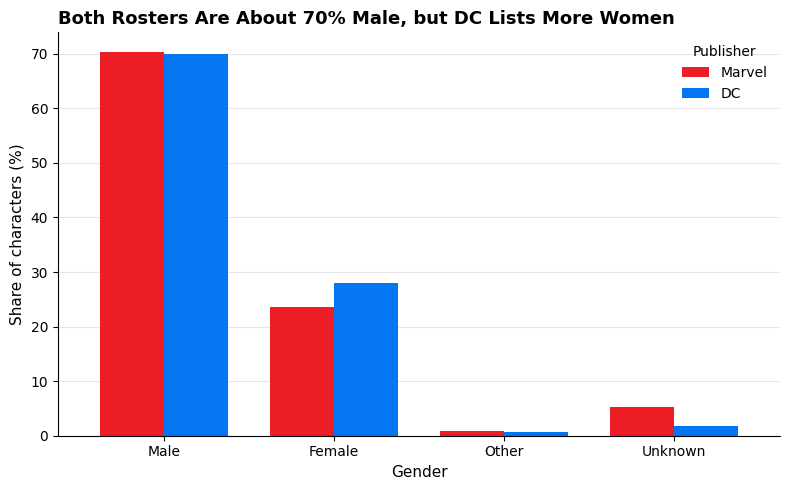

In [ ]:
q1 = comics.pivot_table(index="gender", columns="publisher", values="character", aggfunc="count")
q1 = (q1 / q1.sum() * 100).round(1).loc[["Male", "Female", "Other", "Unknown"], ["Marvel", "DC"]]
print(q1)

fig, ax = plt.subplots(figsize=(8, 5))
q1.plot(kind="bar", ax=ax, rot=0, color=[PUB_COLORS[p] for p in q1.columns], width=0.75)
finish_chart(ax, "Both Rosters Are About 70% Male, but DC Lists More Women",
             "Gender", "Share of characters (%)", legend_title="Publisher")

**Answer:** male characters make up 70.4% of Marvel's roster and 69.9% of DC's. Female characters make up 23.6% of Marvel and 27.9% of DC, a gap of 4.3 percentage points in DC's favor (24.9% vs 28.4% among characters with known gender). Other gender identities are under 1% at both publishers, and gender is unknown for 5.2% of Marvel characters vs 1.7% at DC. **Hypothesis partly confirmed:** both are about 70% male, but DC is not more male; it has more women.

**Interpretation:** both rosters are about 70% male, and Marvel starts from the more skewed baseline of the two.

**Caveat:** gender is recorded by volunteer wiki editors, and Marvel has three times DC's share of unknown gender (5.2% vs 1.7%), most likely among minor characters. Marvel's true split is therefore less certain than DC's.

### Q2. When were the characters in our data created?
**Why it matters:** shows which eras our conclusions can speak to, and whether one publisher's roster is younger than the other's.

**Hypothesis:** most characters debuted after 1960, with a visible 1990s spike, and Marvel's roster skews later.

publisher        DC  Marvel  Total
debut_decade                      
1930.0          245     142    387
1940.0         1053    2211   3264
1950.0          484    1417   1901
1960.0         1011    2263   3274
1970.0          880    4716   5596
1980.0         2159    4980   7139
1990.0         2201    7027   9228
2000.0         1917    6193   8110
2010.0         2188    6411   8599
2020.0          572    1813   2385
Total         12710   37173  49883

Median debut year: {'DC': 1992.0, 'Marvel': 1993.0}
% debuting in 1960 or later: 88.9


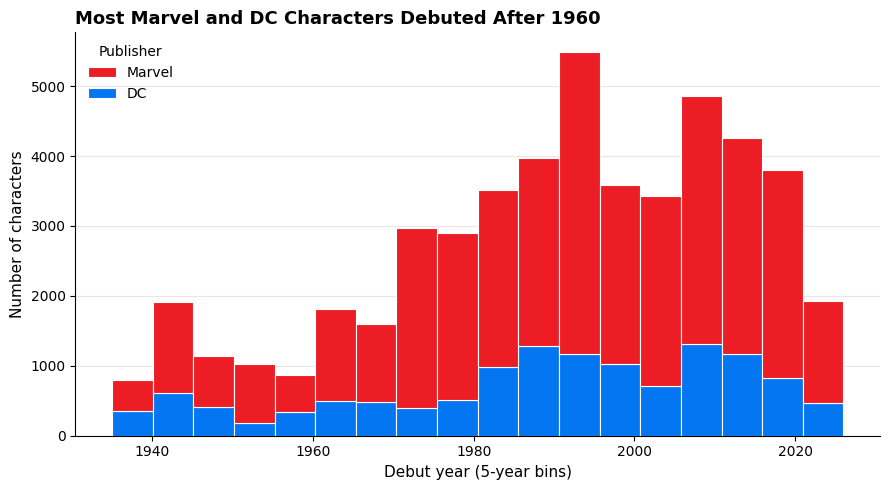

In [ ]:
debut_data = comics.dropna(subset=["debut_year"])
print(debut_data.pivot_table(index="debut_decade", columns="publisher", values="character",
                             aggfunc="count", margins=True, margins_name="Total"))
print("\nMedian debut year:", debut_data.groupby("publisher")["debut_year"].median().to_dict())
print("% debuting in 1960 or later:", round((debut_data["debut_year"] >= 1960).mean() * 100, 1))

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=debut_data, x="debut_year", hue="publisher", hue_order=["Marvel", "DC"],
             palette=PUB_COLORS, multiple="stack", binwidth=5, ax=ax,
             alpha=1, edgecolor="white", linewidth=0.8)
sns.move_legend(ax, "upper left", title="Publisher", frameon=False)
finish_chart(ax, "Most Marvel and DC Characters Debuted After 1960",
             "Debut year (5-year bins)", "Number of characters")

**Answer:** 88.9% of characters debuted in 1960 or later. The 1990s were the busiest decade (9,228 debuts), driven by Marvel (7,027). DC's 1980s, 1990s and 2010s are almost equal (about 2,200 each). The median debut year is 1993 at Marvel and 1992 at DC. **Hypothesis confirmed** on the post-1960 majority and the 1990s spike, **rejected** on Marvel being younger: the medians are one year apart.

**Interpretation:** our conclusions speak mainly to post-1960 comics. The 1930s to 1950s rest on about 5,500 characters, so results for those decades are less certain.

**Caveat:** the 2020s are a partial decade (2,385 debuts so far), and debut year comes from the wiki's category tags.

### Q3. When did female and male characters debut on average at each publisher?
**Why it matters:** tells editorial when each publisher actually started adding women, not just how many it has now.

**Hypothesis:** female characters debut roughly a decade later on average than male ones at both publishers.

In [ ]:
debut_by_gender = comics.groupby(['publisher', 'gender'])['debut_year'].agg(['mean', 'median', 'count']).round(1)

debut_by_gender

mean  median  count
publisher gender                        
DC        Female   1993.3  1996.0   3548
          Male     1986.4  1990.0   8880
          Other    2003.8  2012.0     74
          Unknown  1991.1  1994.0    208
Marvel    Female   1995.2  1997.0   8783
          Male     1988.2  1991.0  26178
          Other    1999.5  2005.0    294
          Unknown  1997.7  2001.0   1918

**Answer:** at Marvel, female characters debuted in 1995.2 on average vs 1988.2 for male characters, a gap of 7.0 years. At DC the averages are 1993.3 and 1986.4, a gap of 6.9 years. The medians show the same picture: a 6-year gap at both publishers. **Hypothesis partly confirmed:** women arrive later, but by about 7 years, not 10.

**Interpretation:** female characters arrived about seven years later than male ones at both publishers, so the female roster is a younger group than the male one, and neither company started earlier than the other.

**Caveat:** a later average only tells us when characters were added, not how important they became. A publisher could push this number up just by adding many minor female characters recently. 31 Marvel and 8 DC characters have no debut year and are left out.

### Q4. How has the share of new female characters changed decade by decade at each publisher?
**Why it matters:** the headline number hides the trend. Editorial needs to know whether the gap is closing and which publisher moved first.

**Hypothesis:** both publishers rise steadily from the 1960s, and DC pulls ahead of Marvel from the 1980s onward.

publisher       DC  Marvel  DC minus Marvel
debut_decade                               
1930          12.7    14.5             -1.8
1940          23.4    13.4             10.0
1950          14.4    16.0             -1.6
1960          17.6    12.6              4.9
1970          20.1    21.3             -1.2
1980          30.2    24.9              5.3
1990          29.7    25.1              4.6
2000          32.9    29.2              3.7
2010          34.7    31.3              3.4
2020          36.5    35.0              1.5


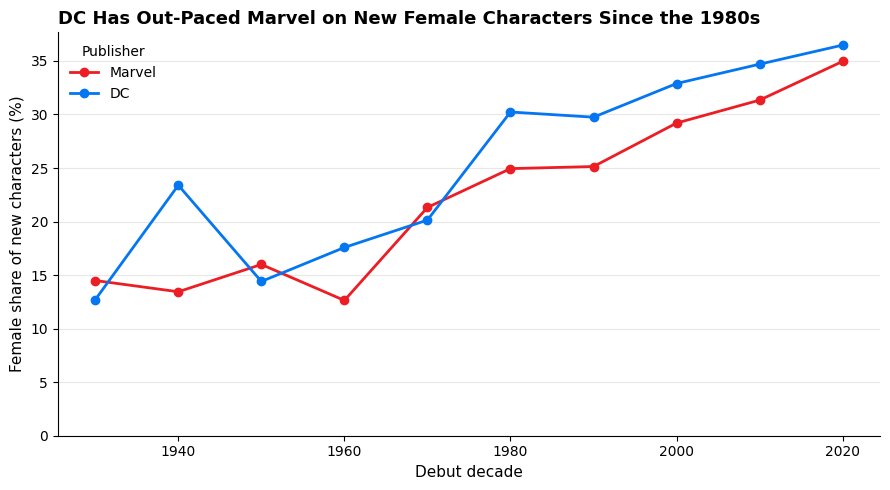

In [ ]:
q4 = known.pivot_table(index="debut_decade", columns="publisher", values="is_female", aggfunc="mean") * 100
q4.index = q4.index.astype(int)
q4["DC minus Marvel"] = q4["DC"] - q4["Marvel"]
print(q4.round(1))

fig, ax = plt.subplots(figsize=(9, 5))
for pub in ["Marvel", "DC"]:
    ax.plot(q4.index, q4[pub], marker="o", linewidth=2, color=PUB_COLORS[pub], label=pub)
ax.set_ylim(0, None)
finish_chart(ax, "DC Has Out-Paced Marvel on New Female Characters Since the 1980s",
             "Debut decade", "Female share of new characters (%)", legend_title="Publisher")

**Answer:** the share of women among new characters grows at both publishers, but not steadily. Before the 1970s the lines cross several times: in the 1940s DC reaches 23.4% while Marvel has 13.4%, then DC falls back to 14.4% in the 1950s, and Marvel hits its low of 12.6% in the 1960s. From the 1980s on, DC leads in five decades in a row, starting at 30.2% against Marvel's 24.9%, and by the 2020s Marvel reaches 35.0% and DC 36.5%. **Hypothesis partly confirmed:** DC does take the lead in the 1980s, as expected, but growth was not steady; it stalls for both publishers in the 1990s.

**Interpretation:** DC leads, but the gap is narrowing: from 5.3 points in the 1980s to 1.5 in the 2020s. Marvel's lower share in the overall roster (Q1) was built up in past decades, when it created most of its characters, and says little about how Marvel creates characters today. For the editorial team, the overall roster figure and the current share of new characters tell different stories, and only the second one is something they can manage.

**Caveat:** a character's decade is the decade of first appearance on the wiki. The 1930s (387 characters) and 1950s rest on fewer characters, so a few characters move the share. DC's 1940s peak, however, rests on 1,053 characters, so it is unlikely to be noise; it may reflect World War II, when women's employment rose and then fell back after the war (before our FRED data starts in 1948). The 2020s are an unfinished decade, and recent characters may not all be on the wiki yet.

## B. Does comics track the workforce, and with what lag?
Here the comics data meets the real world: does the female share of new characters move with women's labor force participation, and how many years behind?

### Q5. Did the share of new female characters rise alongside women's labor force participation since 1948?
**Why it matters:** shows whether the industry moved with society or on its own schedule.

**Hypothesis:** both rise, but the comics line rises later and more slowly.

      pct_female  women_lfpr_pct
year                            
1948        20.8            32.7
1960        11.5            37.8
1980        22.7            51.5
1999        26.9            60.0
2025        40.0            57.3
Correlation: 0.83


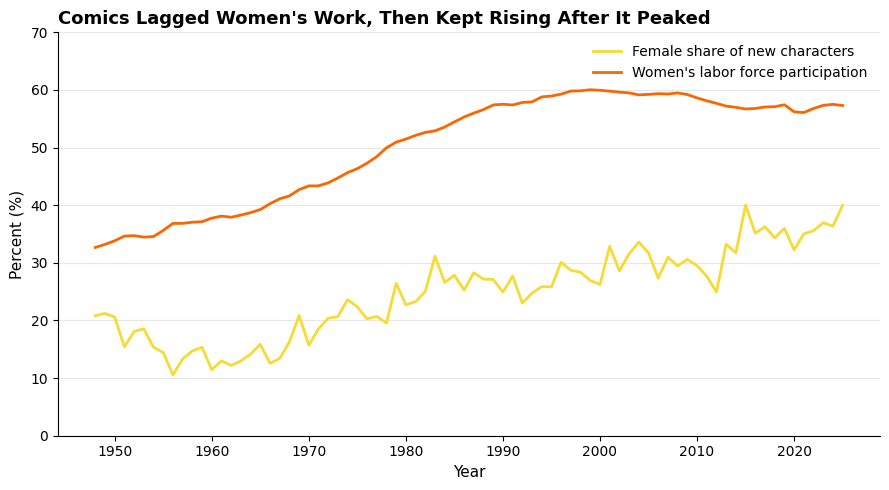

In [ ]:
q5 = comics_fred[comics_fred["year"] <= 2025].set_index("year")[["pct_female", "women_lfpr_pct"]]   # 2026 is partial
print(q5.loc[[1948, 1960, 1980, 1999, 2025]].round(1))
print("Correlation:", round(q5["pct_female"].corr(q5["women_lfpr_pct"]), 2))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(q5.index, q5["pct_female"], color=SOURCE_COLORS["Comics"], linewidth=2, label="Female share of new characters")
ax.plot(q5.index, q5["women_lfpr_pct"], color=SOURCE_COLORS["US workforce"], linewidth=2,
        label="Women's labor force participation")
ax.set_ylim(0, 70)
finish_chart(ax, "Comics Lagged Women's Work, Then Kept Rising After It Peaked",
             "Year", "Percent (%)", legend_title="")

**Answer:** mostly yes (r = 0.83), but not at the same time. Women's labor force participation rose from 32.7% in 1948 to a peak of 60.0% in 1999. The female share of new characters actually fell from 20.8% to 11.5% between 1948 and 1960 and only started rising in the 1960s (22.7% in 1980, 26.9% in 1999). After 1999 participation leveled off near 57%, but comics kept rising to 40.0% in 2025. **Hypothesis confirmed.**

**Interpretation:** comics followed women into the workforce late, and kept catching up after the real change had stopped.

**Caveat:** the two lines measure different things (the share of women who work vs the share of characters who are female), so we compare their direction, not their levels.

### Q6. How closely do the two series move together at 0, 5 and 10 year lags?
**Why it matters:** a first test of how far behind comics are.

**Hypothesis:** the series line up better when comics are compared with the workforce of 5 to 10 years earlier.

Same year           0.83
5 years earlier     0.88
10 years earlier    0.88
dtype: float64


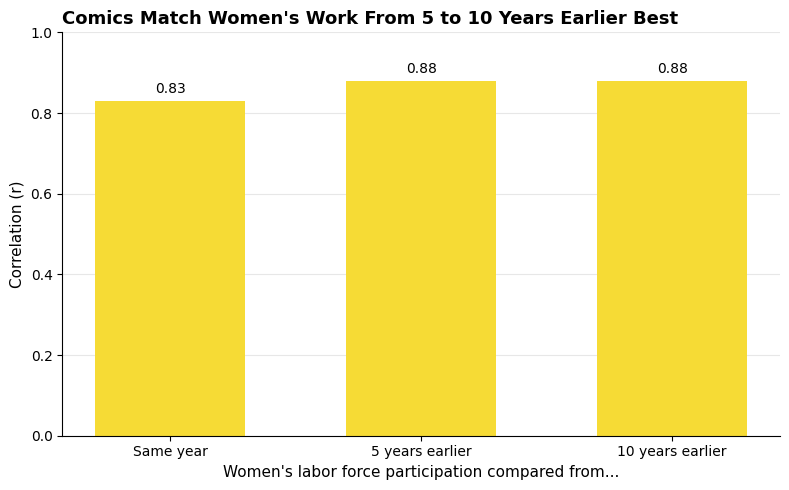

In [ ]:
q6 = pd.Series({
    "Same year": q5["pct_female"].corr(q5["women_lfpr_pct"]),
    "5 years earlier": q5["pct_female"].corr(q5["women_lfpr_pct"].shift(5)),
    "10 years earlier": q5["pct_female"].corr(q5["women_lfpr_pct"].shift(10)),
}).round(2)
print(q6)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(q6.index, q6.values, color=SOURCE_COLORS["Comics"], width=0.6)
for x, v in enumerate(q6.values):
    ax.text(x, v + 0.02, f"{v:.2f}", ha="center")
ax.set_ylim(0, 1)
finish_chart(ax, "Comics Match Women's Work From 5 to 10 Years Earlier Best",
             "Women's labor force participation compared from...", "Correlation (r)")

**Answer:** r = 0.83 for the same year, 0.88 for 5 years earlier and 0.88 for 10 years earlier. **Hypothesis confirmed,** but the improvement is small.

**Interpretation:** comics fit the workforce of a few years earlier slightly better, which suggests a lag. Q7 tests every lag to find the best one.

**Caveat:** both series rise over time, which alone makes the correlations high. Correlation also does not show that one caused the other.

### Q7. Which lag actually fits best?
**Why it matters:** "5 to 10 years" is a range we picked in advance, not a finding. Testing every lag gives editorial a single number for how far behind the industry runs.

**Hypothesis:** the correlation peaks somewhere between 5 and 10 years, but the peak is flat.

0     0.833
1     0.848
2     0.862
3     0.872
4     0.874
5     0.882
6     0.890
7     0.890
8     0.888
9     0.883
10    0.877
11    0.873
12    0.873
13    0.872
14    0.869
15    0.867
dtype: float64
best lag: 7 years, r = 0.89


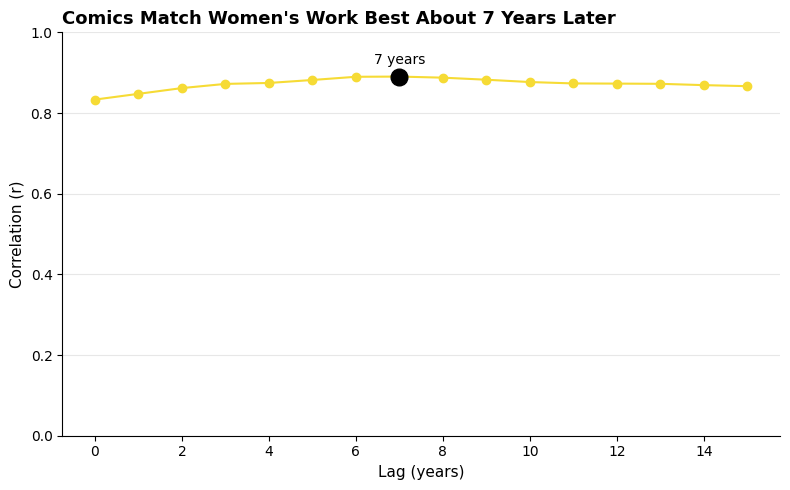

In [ ]:
lags = []
corrs = []
for lag in range(16):
    lags.append(lag)
    corrs.append(q5["pct_female"].corr(q5["women_lfpr_pct"].shift(lag)))

lag_results = pd.Series(corrs, index=lags)
print(lag_results.round(3))

best_lag = lag_results.idxmax()
print("best lag:", best_lag, "years, r =", round(lag_results.max(), 3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(lag_results.index, lag_results.values, marker="o", color=SOURCE_COLORS["Comics"])
ax.plot(best_lag, lag_results.max(), marker="o", markersize=12, color="black")
ax.text(best_lag, lag_results.max() + 0.03, f"{best_lag} years", ha="center")
ax.set_ylim(0, 1)
finish_chart(ax, "Comics Match Women's Work Best About 7 Years Later",
             "Lag (years)", "Correlation (r)")

**Answer:** the best fit is a 7-year lag (r = 0.89), against 0.83 with no lag. Lags from 5 to 9 years fit almost as well (r = 0.88 to 0.89). **Hypothesis confirmed:** the peak sits between 5 and 10 years, and it is flat.

**Interpretation:** comics match the workforce of about 7 years earlier best, but the peak is flat (any lag from 5 to 9 years fits almost as well), so 7 years is a rough estimate, not a precise delay. Q8 shows the same flat pattern for each publisher.

**Caveat:** both lines rise over time, so the correlation is high at every lag, and the flat peak means "7 years" should be read as "roughly 5 to 9 years". Correlation also does not prove that one caused the other.

### Q8. Does the lag differ between Marvel and DC?
**Why it matters:** if one publisher tracks society more closely, that is a competitive difference editorial can point to, and it answers "which publisher mirrors reality better" directly.

**Hypothesis:** DC's best-fitting lag is shorter than Marvel's, consistent with DC pulling ahead on female characters from the 1980s.

    Marvel     DC
0    0.800  0.761
1    0.810  0.786
2    0.813  0.817
3    0.827  0.820
4    0.827  0.830
5    0.835  0.839
6    0.850  0.835
7    0.854  0.832
8    0.849  0.830
9    0.843  0.823
10   0.840  0.812
11   0.845  0.804
12   0.843  0.801
13   0.845  0.792
14   0.844  0.778
15   0.842  0.764
Marvel: best lag 7 years, r = 0.854
DC: best lag 5 years, r = 0.839


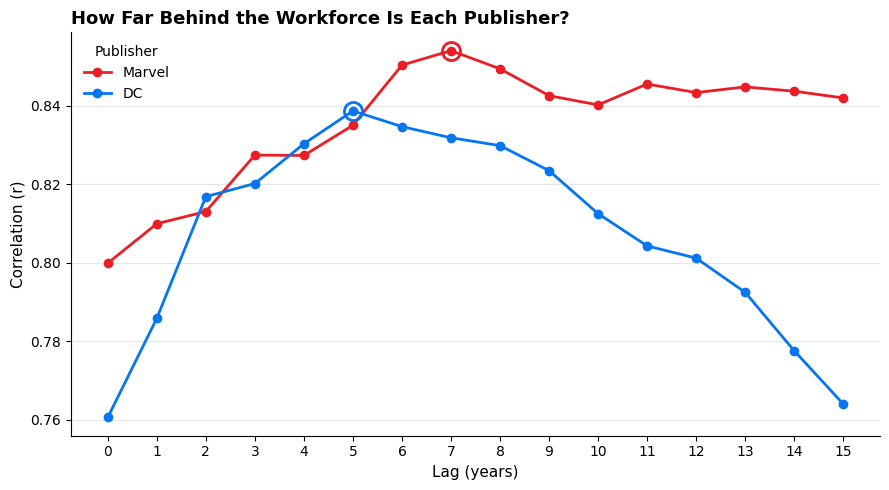

In [ ]:
def lag_curve(yearly, max_lag=15):
    """Correlation between a yearly female-share series and women's labor force participation
    from `lag` years earlier, for lag = 0..max_lag (same method as Q7)."""
    df = (yearly.merge(fred_yearly[["year", "women_lfpr_pct"]], on="year")
                .set_index("year").loc[:2025])                       # 2026 is a partial year
    df = df.reindex(range(df.index.min(), df.index.max() + 1))      # one row per year, so shift(n) = n years
    return pd.Series({lag: df["pct_female"].corr(df["women_lfpr_pct"].shift(lag)) for lag in range(max_lag + 1)})

q8 = pd.DataFrame({pub: lag_curve(yearly_female_share(comics[comics["publisher"] == pub]))
                   for pub in ["Marvel", "DC"]})
print(q8.round(3))
for pub in q8.columns:
    print(f"{pub}: best lag {q8[pub].idxmax()} years, r = {q8[pub].max():.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
for pub in q8.columns:
    ax.plot(q8.index, q8[pub], marker="o", linewidth=2, color=PUB_COLORS[pub], label=pub)
    ax.plot(q8[pub].idxmax(), q8[pub].max(), marker="o", markersize=13, markerfacecolor="none",
            markeredgecolor=PUB_COLORS[pub], markeredgewidth=2)
ax.set_xticks(q8.index)
finish_chart(ax, "How Far Behind the Workforce Is Each Publisher?",
             "Lag (years)", "Correlation (r)", legend_title="Publisher")

**Answer:** Marvel's correlation peaks at a 7-year lag (r = 0.854) and DC's at 5 years (r = 0.839), so DC's best match comes 2 years earlier. **Hypothesis confirmed on paper,** but the difference is small: across all 16 lags, Marvel stays between 0.800 and 0.854 and DC between 0.761 and 0.839.

**Interpretation:** a 2-year difference falls inside this flat range, so we cannot say that DC reacts to society faster than Marvel. For both publishers, the female share of new characters simply grew in the same decades as women's labor force participation, and no business decision should rest on the 2-year gap.

**Caveat:** two rising lines correlate strongly whether or not they are linked, so an r of about 0.8 does not prove that comics respond to the labor market. A real reaction time would show a clear peak with a drop on both sides. DC's curve does rise and fall around 5 years, but only by about 0.08; Marvel's is almost flat from 6 years on.

## C. What jobs do female characters get?
The core of the project: not how many women comics create, but what they are allowed to do. We first look at the raw casting pattern, then compare it with the real workforce.

### Q9. What jobs do female and male characters actually get?
**Why it matters:** before comparing to the census, the reader needs to see the raw casting pattern: what writers actually hand male and female characters.

**Hypothesis:** male characters cluster in Criminal, Military and manual jobs, while female characters concentrate in professional, clerical and service roles.

gender                  Female  Male  Female minus Male
occ_group                                              
Professional/Technical    22.0  20.1                1.9
Criminal                  13.8  21.3               -7.5
Royalty/Mystic            12.5   9.0                3.5
Hero/Adventurer            8.5   6.2                2.3
Student                    7.9   3.4                4.4
Other                      7.7   7.7               -0.1
Military                   5.3   9.0               -3.7
Spy/Agent                  5.2   5.2                0.1
Service                    4.7   4.9               -0.2
Managers/Officials         3.9   7.1               -3.2
Not working                3.6   1.8                1.9
Clerical                   2.4   0.6                1.7
Private household          0.9   0.5                0.4
Farmers                    0.5   0.7               -0.3
Craftsmen                  0.4   0.8               -0.4
Laborers                   0.3   0.5            

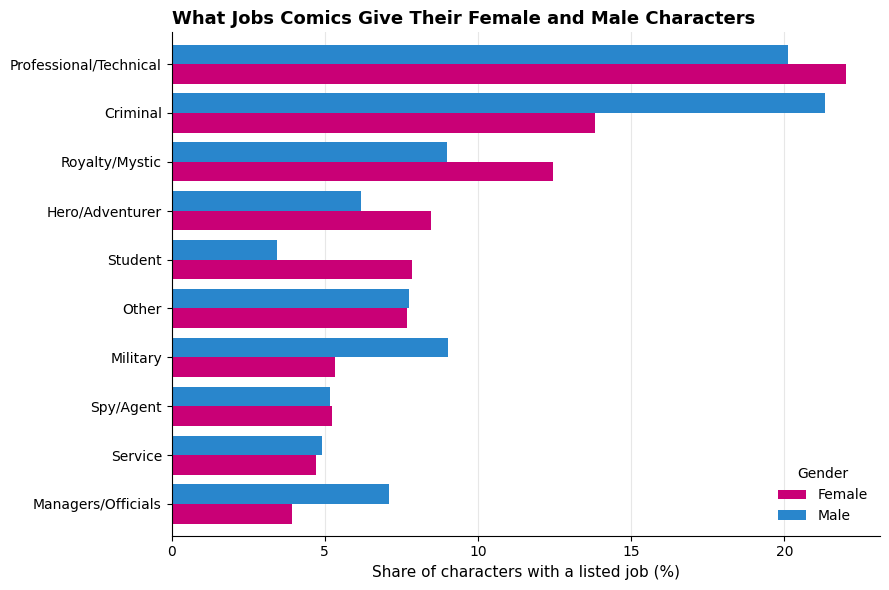

In [ ]:
with_job = comics[comics["gender"].isin(["Female", "Male"]) & (comics["occ_group"] != "Unknown")]
q9 = (pd.crosstab(with_job["occ_group"], with_job["gender"], normalize="columns") * 100)
q9["Female minus Male"] = q9["Female"] - q9["Male"]
q9 = q9.sort_values("Female", ascending=False)
print(q9.round(1))

top = q9.head(10)[["Female", "Male"]].iloc[::-1]    # 10 biggest groups for women, largest at the top
fig, ax = plt.subplots(figsize=(9, 6))
top.plot(kind="barh", ax=ax, color=[GENDER_COLORS[g] for g in top.columns], width=0.8)
finish_chart(ax, "What Jobs Comics Give Their Female and Male Characters",
             "Share of characters with a listed job (%)", "", legend_title="Gender", grid="x")

**Answer:** among characters with a listed occupation, women's most common groups are Professional/Technical (22.0%), Criminal (13.8%) and Royalty/Mystic (12.5%); men's are Criminal (21.3%), Professional/Technical (20.1%), and Military and Royalty/Mystic (9.0% each). Men are much more often Criminal (+7.5 points), Military (+3.7) and Managers/Officials (+3.2); women are more often Students (+4.4), Royalty/Mystic (+3.5), Hero/Adventurer (+2.3), Not working (+1.9) and Clerical (+1.7). **Hypothesis partly confirmed:** men do cluster in Criminal and Military roles, but not in manual jobs (every manual group is under 1% for both genders), and women are not concentrated in clerical or service work: Professional/Technical is the top group for both, and Service is almost equal (4.7% vs 4.9%).

**Interpretation:** most comic jobs are fantasy roles for both genders. The difference is in power and age: men are more often written as criminals, soldiers and bosses, women more often as students, mystics or without work. Clerical work is four times more common for women (2.4% vs 0.6%), but it is a small group.

**Caveat:** each character is counted under one job only (the first one listed), the job groups are broad, and the chart pools all decades, so it does not show how the pattern changed over time (see Q12).

### Q10. Do female characters hold jobs where real U.S. women are more common than in male characters' jobs?
**Why it matters:** the core question for editorial: are female characters handed the jobs society already codes as women's work?

**Hypothesis:** female characters sit in job groups with a higher real-world female share than male characters' jobs.

        count  mean  median
gender                     
Female   2475  50.1    51.5
Male     8357  42.9    43.0
gender        Female  Male  gap
debut_decade                   
1940.0          39.5  33.6  5.9
1950.0          32.1  30.5  1.6
1960.0          40.7  34.6  6.1
1970.0          44.6  37.3  7.3
1980.0          48.4  42.6  5.8
1990.0          52.0  48.9  3.1
2000.0          54.6  51.0  3.6
2010.0          54.2  50.6  3.6
2020.0          52.0  48.8  3.2
Average gap across decades: 4.5


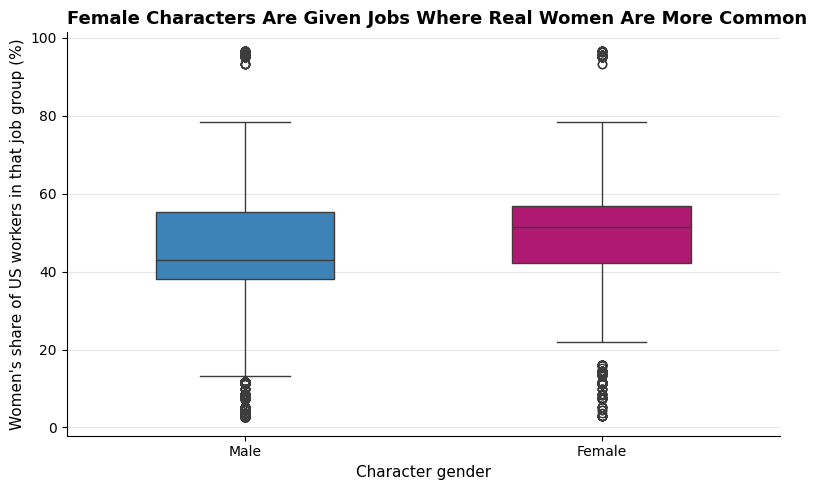

In [ ]:
jobs_by_gender = comics_jobs[comics_jobs["gender"].isin(["Female", "Male"])].dropna(subset=["us_pct_women"])
print(jobs_by_gender.groupby("gender")["us_pct_women"].agg(["count", "mean", "median"]).round(1))

by_decade = jobs_by_gender.pivot_table(index="debut_decade", columns="gender", values="us_pct_women").round(1)
by_decade["gap"] = by_decade["Female"] - by_decade["Male"]
print(by_decade)
print("Average gap across decades:", round(by_decade["gap"].mean(), 1))

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=jobs_by_gender, x="gender", y="us_pct_women", order=["Male", "Female"],
            hue="gender", palette=GENDER_COLORS, legend=False, width=0.5, ax=ax)
finish_chart(ax, "Female Characters Are Given Jobs Where Real Women Are More Common",
             "Character gender", "Women's share of US workers in that job group (%)")

**Answer:** yes. The jobs of female characters are on average 50.1% female in the real workforce (median 51.5%), against 42.9% for male characters (median 43.0%), based on 2,475 female and 8,357 male characters with a census job. Female characters' jobs are "more female" in every decade from the 1940s to the 2020s, by 4.5 points on average (largest in the 1970s, 7.3 points). **Hypothesis confirmed.**

**Interpretation:** writers place female characters in the parts of the economy where women already worked, so comics reproduce the real-world split instead of challenging it.

**Caveat:** the measure works at the level of 11 broad job groups, so it shows which groups characters are put in, not individual jobs. Only characters with a census-type job (about 22% of the roster) are included.

### Q11. Job group by job group, how does the female share in comics compare with the real workforce?
**Why it matters:** the boxplot shows a difference on average but hides where it comes from. Editorial can act on "we under-cast women as professionals"; it cannot act on "the distributions differ".

**Hypothesis:** comics under-represent women in most job groups, and the gap is widest in professional and technical jobs.

                           n  Comics  US workforce   gap
occ_group                                               
Private household        124    36.3          95.7 -59.5
Service                 1453    22.8          56.1 -33.3
Sales                     96    15.6          40.5 -24.9
Professional/Technical  6198    25.0          48.1 -23.2
Clerical                 312    53.5          72.8 -19.3
Operatives               194     8.8          28.0 -19.2
Managers/Officials      1926    14.3          28.8 -14.5
Laborers                 133    13.5           8.3   5.2
Craftsmen                208    12.5           6.2   6.3
Farmers                  184    16.8           6.3  10.6
Farm laborers              4    50.0          18.7  31.3
Left out (fewer than 20 characters): ['Farm laborers']


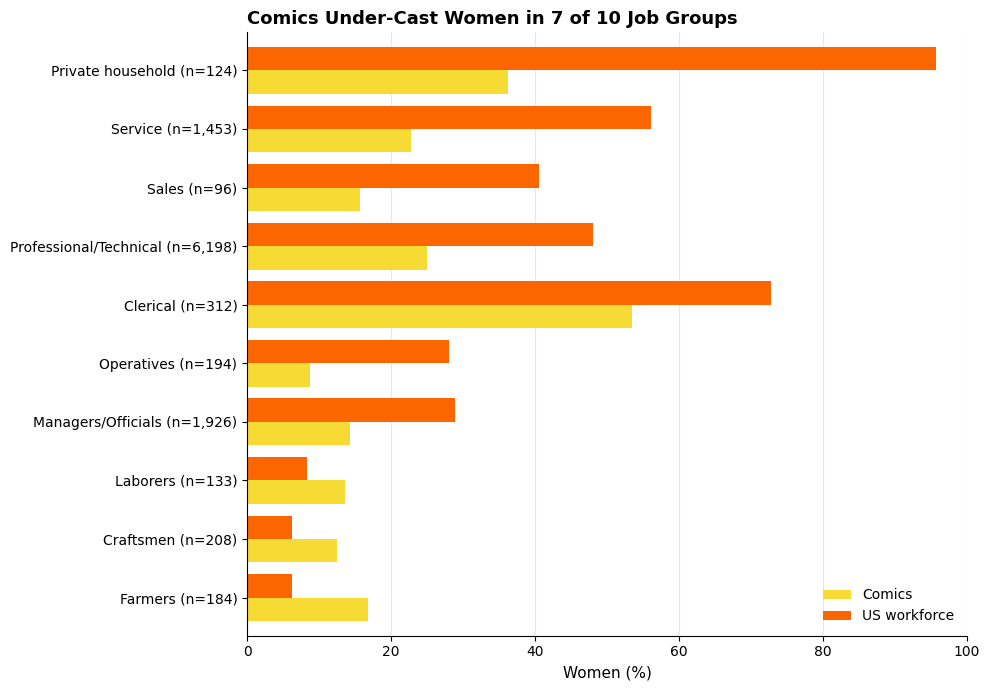

In [ ]:
MIN_N = 20   # job groups with fewer characters than this are too small to compare
q11 = (jobs_by_gender.groupby("occ_group")
       .agg(n=("gender", "size"),
            Comics=("gender", lambda g: (g == "Female").mean() * 100),
            **{"US workforce": ("us_pct_women", "mean")}))
q11["gap"] = q11["Comics"] - q11["US workforce"]
print(q11.round(1).sort_values("gap"))
print("Left out (fewer than", MIN_N, "characters):", list(q11.index[q11["n"] < MIN_N]))
q11 = q11[q11["n"] >= MIN_N].sort_values("gap")

plot_df = q11.iloc[::-1]   # largest shortfall at the top
fig, ax = plt.subplots(figsize=(10, 7))
plot_df[["Comics", "US workforce"]].plot(kind="barh", ax=ax, width=0.8,
                                         color=[SOURCE_COLORS["Comics"], SOURCE_COLORS["US workforce"]])
ax.set_yticklabels([f"{g} (n={n:,})" for g, n in plot_df["n"].items()])
ax.set_xlim(0, 100)
n_under = (q11["gap"] < 0).sum()
finish_chart(ax, f"Comics Under-Cast Women in {n_under} of {len(q11)} Job Groups",
             "Women (%)", "", legend_title="", grid="x")

**Answer:** comics under-represent women in every large non-manual job group: Private household (-59.5 points vs reality), Service (-33.3), Sales (-24.9), Professional/Technical (-23.2), Clerical (-19.3), Operatives (-19.2) and Managers/Officials (-14.5). Comics have more women than reality only in small manual groups where real women are under 10% (Farmers +10.6, Craftsmen +6.3, Laborers +5.2). Farm laborers are left out because too few characters hold that job. **Hypothesis partly confirmed:** women are under-cast almost everywhere, but the widest gaps are in household, service and sales jobs, not professional ones.

**Interpretation:** the shortfall is largest in jobs real women dominate, which means comics give most ordinary jobs to men; the female characters who do hold jobs are concentrated in a few groups.

**Caveat:** the U.S. share is weighted by the decades in which each group's characters debuted, and the comics share depends on how many characters of each gender hold a census-type job at all (see Q15).

### Q12. Has that gap narrowed decade by decade?
**Why it matters:** shows whether the industry corrected itself over time, or whether certain jobs stayed stubbornly male on the page.

**Hypothesis:** the gap narrows overall after the 1970s, but some job groups barely move.

Average gap per decade across job groups (points):
debut_decade
1940    -9.3
1950   -16.3
1960   -24.2
1970   -14.9
1980   -15.8
1990   -20.0
2000   -16.0
2010   -11.5
2020    -3.5
dtype: float64


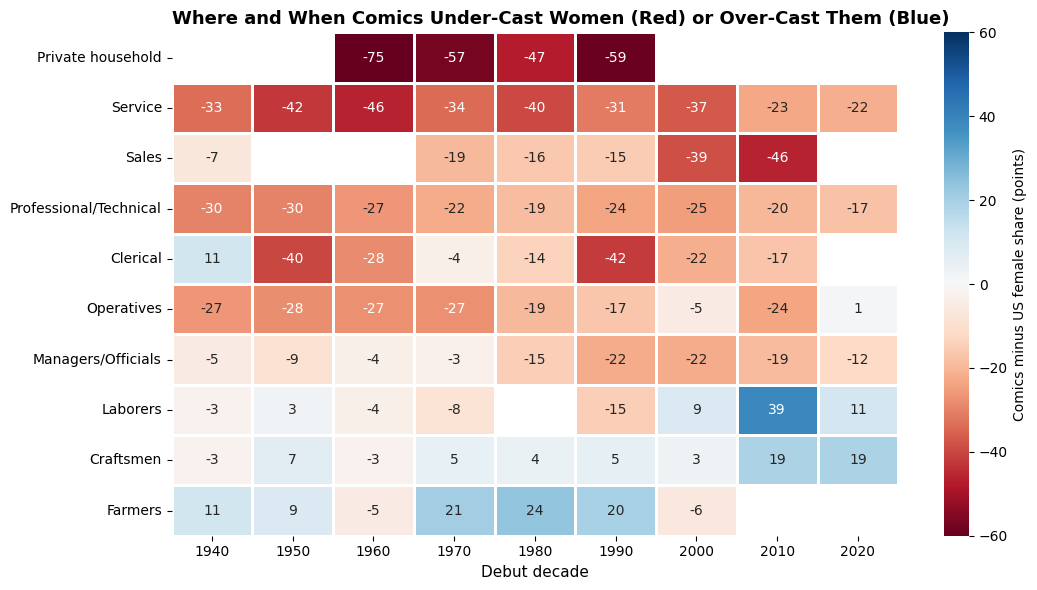

In [ ]:
MIN_CELL = 10   # a decade x job group cell needs at least 10 characters to be shown
cells = (jobs_by_gender.groupby(["occ_group", "debut_decade"])
         .agg(n=("gender", "size"),
              comics=("gender", lambda g: (g == "Female").mean() * 100),
              us=("us_pct_women", "mean")))
cells["gap"] = (cells["comics"] - cells["us"]).where(cells["n"] >= MIN_CELL)
q12 = cells["gap"].unstack()
q12.columns = q12.columns.astype(int)
q12 = q12.dropna(how="all").loc[lambda d: d.mean(axis=1).sort_values().index]

print("Average gap per decade across job groups (points):")
print(q12.mean().round(1))

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(q12, cmap="RdBu", center=0, vmin=-60, vmax=60, annot=True, fmt=".0f",
            linewidths=1, linecolor="white", cbar_kws={"label": "Comics minus US female share (points)"}, ax=ax)
ax.set_title("Where and When Comics Under-Cast Women (Red) or Over-Cast Them (Blue)",
             fontsize=13, weight="bold", loc="left")
ax.set_xlabel("Debut decade", fontsize=11)
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Answer:** partly. Averaged across job groups, the gap was widest in the 1960s (-24.2 points), still -20.0 in the 1990s, and then narrowed to -11.5 in the 2010s and -3.5 in the 2020s. But the two largest groups never closed: Service stayed between -22 and -46 points and Professional/Technical between -17 and -30 in every decade. **Hypothesis partly confirmed:** the gap narrowed, but only from the 1990s on, not after the 1970s, and the biggest job groups barely moved.

**Interpretation:** the recent improvement comes mostly from smaller manual groups (Laborers and Craftsmen now have more women in comics than in reality), not from the jobs where most characters actually work.

**Caveat:** blank cells have fewer than 10 characters, so each decade's average covers different job groups. The 2020s average leaves out Private household, Clerical and Sales, which all have large negative gaps, so -3.5 overstates the improvement. The 2020s are also an unfinished decade.

### Q13. When did female characters start appearing in traditionally male jobs, and how long after real women did?

**Why it matters:** this is the question the proposal set out to answer. Rising headcount means little if women are added into the same narrow set of roles; the real test is whether they enter the jobs that were closed to them.

**Hypothesis:** female characters do move into male-dominated jobs over time, but the shift starts later than it did in the real workforce, roughly in line with the overall lag measured in Q7.

Women's share of each job group in 1940 (%):
occ_group
Craftsmen                  2.6
Laborers                   2.7
Farmers                    3.0
Farm laborers             11.0
Managers/Officials        11.7
Operatives                26.6
Sales                     28.1
Service                   38.2
Professional/Technical    43.0
Clerical                  51.2
Private household         93.2
Name: pct_women, dtype: float64

Male-dominated groups: ['Craftsmen', 'Farm laborers', 'Farmers', 'Laborers', 'Managers/Officials', 'Operatives', 'Sales']
      characters  Comics  US workforce  % of female characters in these jobs
1940         267     7.5          12.8                                   3.7
1950         224     6.7          15.8                                   5.2
1960         184     7.6          16.4                                   3.2
1970         329    12.2          19.5                                   3.5
1980         408    13.0          23.4                          

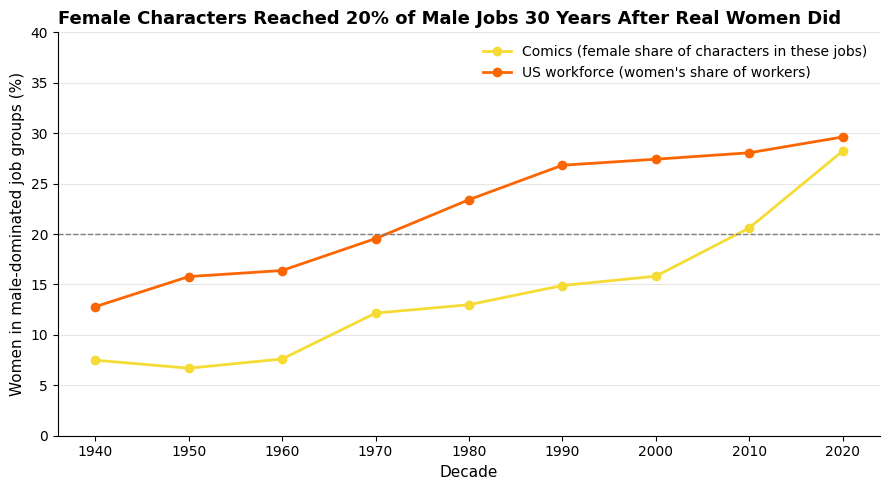

In [ ]:
# Step 1: flag the male-dominated job groups using the earliest census decade (1940)
first_census = jobs[jobs["decade"] == jobs["decade"].min()]
start = first_census.groupby("occ_group")[["women_employed", "total_employed"]].sum()
start["pct_women"] = start["women_employed"] / start["total_employed"] * 100
print("Women's share of each job group in 1940 (%):")
print(start["pct_women"].round(1).sort_values())

male_jobs = start[start["pct_women"] < 30].index.tolist()   # under 30% women = male-dominated
print("\nMale-dominated groups:", male_jobs)

q13 = comics_jobs[comics_jobs["gender"].isin(["Female", "Male"])].copy()
q13["male_dominated"] = q13["occ_group"].isin(male_jobs)
q13 = q13[q13["debut_decade"] >= 1940]   # census starts in 1940

# Step 2: comics - share of characters in male-dominated jobs who are female, per decade
in_male_jobs = q13[q13["male_dominated"]]
comics_line = in_male_jobs.groupby("debut_decade")["gender"].apply(lambda g: (g == "Female").mean() * 100)

# real world - share of workers in the same groups who are women, per decade
us = jobs[jobs["occ_group"].isin(male_jobs)].groupby("decade")[["women_employed", "total_employed"]].sum()
us_line = us["women_employed"] / us["total_employed"] * 100

# also: what % of new female characters get one of these jobs at all
landing = q13[q13["gender"] == "Female"].groupby("debut_decade")["male_dominated"].mean() * 100

q13_table = pd.DataFrame({"characters": in_male_jobs.groupby("debut_decade").size(),
                          "Comics": comics_line,
                          "US workforce": us_line,
                          "% of female characters in these jobs": landing})
q13_table.index = q13_table.index.astype(int)
print(q13_table.round(1))

# Step 3: when did each one first reach 15%, 20% and 25% women, and how many years apart?
for level in [15, 20, 25]:
    us_year = q13_table[q13_table["US workforce"] >= level].index.min()
    comics_year = q13_table[q13_table["Comics"] >= level].index.min()
    print(f"{level}% women -> US workforce: {us_year}s, comics: {comics_year}s, lag: {comics_year - us_year} years")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(q13_table.index, q13_table["Comics"], marker="o", linewidth=2,
        color=SOURCE_COLORS["Comics"], label="Comics (female share of characters in these jobs)")
ax.plot(q13_table.index, q13_table["US workforce"], marker="o", linewidth=2,
        color=SOURCE_COLORS["US workforce"], label="US workforce (women's share of workers)")
ax.axhline(20, color="gray", linestyle="--", linewidth=1)
ax.set_ylim(0, 40)
finish_chart(ax, "Female Characters Reached 20% of Male Jobs 30 Years After Real Women Did",
             "Decade", "Women in male-dominated job groups (%)", legend_title="")

**Answer:** seven job groups were under 30% women in the 1940 census: Craftsmen, Laborers, Farmers, Farm laborers, Managers/Officials, Operatives and Sales. In the real workforce, women already made up 12.8% of these jobs in the 1940s and reached 20% in the 1980s (23.4%). In comics, female characters stayed around 7% of these jobs from the 1940s to the 1960s, only started rising in the 1970s (12.2%), and passed 20% in the 2010s (20.6%), reaching 28.2% in the 2020s, close to the real 29.6%. Comics reached the 15% mark 50 years after the workforce did, and the 20% and 25% marks 30 years after. **Hypothesis partly confirmed:** female characters do move into male jobs, and later than real women, but the lag is 30 to 50 years, not the 7 years from Q7.

**Interpretation:** comics added women to the roster in general much faster than they gave them traditionally male jobs. Writers created more female characters, but kept handing them the jobs women already held. Only 2% to 5% of new female characters in any decade work in one of these groups, and that share has barely moved since the 1940s. The gap with reality only closed in the 2020s.

**Caveat:** the "male-dominated" label is fixed in 1940 and uses 7 broad census groups, so it misses jobs inside other groups that were male (for example doctors or engineers inside Professional/Technical). Only characters with a census-type job are included (a few hundred per decade), and the 2020s are an unfinished decade with 124 characters.

### Q14. Which job groups changed most for women, in comics and in reality?

**Why it matters:** names the specific occupations where comics changed fastest and where they stalled, which is what an editorial team would use to pick the next character's profession.

**Hypothesis:** professional and clerical groups change most in both comics and reality, while manual groups move least in comics.

                        Comics then  Comics now  US then  US now  \
occ_group                                                          
Laborers                        1.9        27.8      3.3    11.9   
Service                         4.5        28.1     46.5    59.1   
Professional/Technical         12.2        32.0     40.0    56.1   
Craftsmen                       2.0        18.6      2.8     7.7   
Private household              18.5        34.8     95.0    95.1   
Operatives                      0.0        14.0     27.3    24.9   
Managers/Officials              7.4        18.1     13.4    39.9   
Farmers                        11.2        20.5      3.4    14.4   
Clerical                       45.2        50.0     62.5    74.2   
Sales                          18.5         9.3     33.2    46.0   

                        Comics change  US change  
occ_group                                         
Laborers                         25.9        8.6  
Service                       

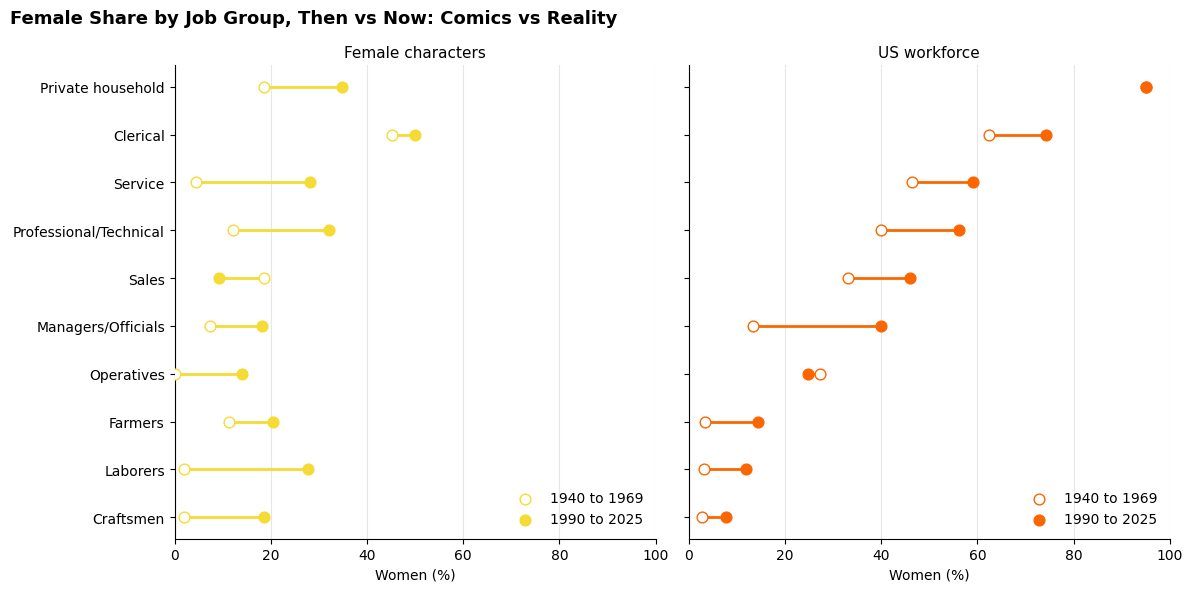

In [ ]:
ERAS = {"1940 to 1969": (1940, 1969), "1990 to 2025": (1990, 2025)}
MIN_ERA = 15   # characters needed per job group in each era

def era_of(year):
    for name, (lo, hi) in ERAS.items():
        if lo <= year <= hi:
            return name
    return None

census_groups = jobs_by_group["occ_group"].unique()
mf = comics[comics["gender"].isin(["Female", "Male"]) & comics["occ_group"].isin(census_groups)].copy()
mf["era"] = mf["debut_year"].apply(era_of)
comics_era = mf.dropna(subset=["era"]).groupby(["occ_group", "era"])["gender"].agg(
    share=lambda g: (g == "Female").mean() * 100, n="size").unstack()

jobs_era = jobs.assign(era=jobs["year"].apply(era_of)).dropna(subset=["era"])
us_era = jobs_era.groupby(["occ_group", "era"])[["women_employed", "total_employed"]].sum()
us_era = (us_era["women_employed"] / us_era["total_employed"] * 100).unstack()

then, now = ERAS
keep = comics_era["n"].min(axis=1) >= MIN_ERA
q14 = pd.DataFrame({"Comics then": comics_era["share"][then], "Comics now": comics_era["share"][now],
                    "US then": us_era[then], "US now": us_era[now]}).loc[keep[keep].index]
q14["Comics change"] = q14["Comics now"] - q14["Comics then"]
q14["US change"] = q14["US now"] - q14["US then"]
q14 = q14.sort_values("US now")
print(q14.round(1).sort_values("Comics change", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
for ax, (side, color) in zip(axes, [("Comics", SOURCE_COLORS["Comics"]), ("US", SOURCE_COLORS["US workforce"])]):
    y = range(len(q14))
    ax.hlines(y, q14[f"{side} then"], q14[f"{side} now"], color=color, linewidth=2)
    ax.scatter(q14[f"{side} then"], y, s=60, facecolor="white", edgecolor=color, zorder=3, label=then)
    ax.scatter(q14[f"{side} now"], y, s=60, color=color, zorder=3, label=now)
    ax.set_yticks(list(y), q14.index)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Women (%)")
    ax.set_title("Female characters" if side == "Comics" else "US workforce", fontsize=11)
    ax.grid(axis="x", alpha=0.3)
    ax.legend(frameon=False, loc="lower right")
    sns.despine(ax=ax)
fig.suptitle("Female Share by Job Group, Then vs Now: Comics vs Reality", fontsize=13, weight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**Answer:** comics saw the largest increases in the female share in Laborers (+25.9 points), Service (+23.6) and Professional/Technical (+19.9). Only one group declined: Sales, where the female share fell from 18.5% to 9.3% (-9.2 points). In reality, the largest increase was in Managers/Officials (+26.5 points), and this is exactly where the biggest gap lies: comics gained only 10.7 points, 15.8 less than reality. **Hypothesis rejected:** we expected professional and clerical groups to shift the most and manual groups the least, but manual groups grew the most in comics, while Clerical was among the slowest (+4.8).

**Interpretation:** where real women made their biggest shift, management, comics barely responded: in 1990 to 2025 real women held 39.9% of these jobs, against 18.1% of comic characters. At the same time, comics added women to manual roles far faster than reality did. For the editorial team, this points to a clear gap: the pages lack women who hold authority over others, and women in ordinary commercial work, where comics moved in the opposite direction to the country.

**Caveat:** we compare 1940 to 1969 with 1990 to 2025 and leave out the years in between, so the two periods are clearly separated. This split is our choice, and a different one would shift every figure. In Private household the real change is only 0.1 points because the job was already almost entirely female. The census counts people employed in a period, while comics count characters created in that period, whether or not they are ever shown at work.

## D. Are women written with working lives?
Sections A to C looked at which jobs characters hold. This last section asks a more basic question: do female characters get an occupation at all?

### Q15. Are female characters less likely than male characters to have an occupation listed?

**Why it matters:** if female characters are less often given a profession at all, they’re written as identities rather than as people with working lives.

**Hypothesis:** female characters are less likely than male characters to have any occupation listed.

In [ ]:
job_listed = comics[comics["gender"].isin(["Female", "Male"])].copy()
job_listed["has_job"] = job_listed["occ_group"] != "Unknown"
job_listed_table = job_listed.groupby("gender")["has_job"].agg(["mean", "count"])
job_listed_table["mean"] = (job_listed_table["mean"] * 100).round(1)
job_listed_table = job_listed_table.rename(columns={
    "mean": "Percent with Job",
    "count": "Number of Characters"
})
print(job_listed_table)

        Percent with Job  Number of Characters
gender                                        
Female              57.1                 12334
Male                66.7                 35086


**Answer:** yes. 57.1% of female characters have a job listed, against 66.7% of male characters, a gap of 9.6 points (12,334 female and 35,086 male characters). **Hypothesis confirmed.**

**Interpretation:** Female characters are more often written without a job. Comics give them a role in the story, but less often a working life than male characters.

**Caveat:** “Has a job” means any occupation except Unknown. So it also counts “Not working” (like housewife or retired) and “Other” (like robots). In Q9, “Not working” is more common for women (3.6%) than for men (1.8%), so the real job gap is probably a bit bigger than 9.6 points. Also, “no job listed” does not always mean the character has no job. The job may just be missing from the data.

### Q16. Has that changed over time?

**Why it matters:** tells editorial whether the habit of writing women without a working life is historical or still current, which decides whether it needs fixing now.

**Hypothesis:** the gap narrows for characters created after the 1980s but does not fully close.

gender        Female  Male
debut_decade              
1930            62.7  84.0
1940            68.2  79.6
1950            57.4  75.0
1960            54.3  68.7
1970            54.3  70.5
1980            57.3  66.6
1990            55.4  64.0
2000            57.2  65.2
2010            57.9  60.8
2020            56.7  55.0


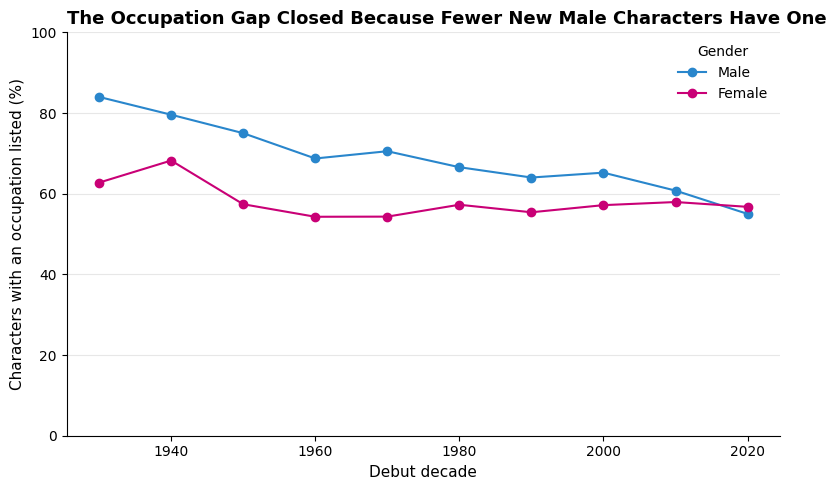

In [ ]:
q16 = job_listed.pivot_table(index="debut_decade", columns="gender", values="has_job", aggfunc="mean") * 100
q16.index = q16.index.astype(int)
print(q16.round(1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(q16.index, q16["Male"], marker="o", color=GENDER_COLORS["Male"], label="Male")
ax.plot(q16.index, q16["Female"], marker="o", color=GENDER_COLORS["Female"], label="Female")
ax.set_ylim(0, 100)
finish_chart(ax, "The Occupation Gap Closed Because Fewer New Male Characters Have One",
             "Debut decade", "Characters with an occupation listed (%)", legend_title="Gender")

**Answer:** In the 1940s, 68.2% of female characters had a job listed, against 79.6% of male characters, a gap of 11.4 points. The gap got smaller over time: 9.3 points in the 1980s and 2.9 points in the 2010s. In the 2020s it closed completely, at 56.7% for women and 55.0% for men.

**Hypothesis partly confirmed:** the gap did narrow after the 1980s, but unlike we expected, it closed completely in the 2020s.

**Interpretation:** Women did not catch up by getting more jobs. Since the 1950s, female characters have stayed around 54 to 58%. The gap closed because male characters went down, from 84.0% in the 1930s to 55.0% in the 2020s. So the gap did not close because more female characters have a job listed. It closed because fewer new male characters have one.

**Caveat:** The 2020s are not finished yet, so the last point may change. The 1930s have only 387 characters. Like in Q15, “has a job” also counts groups like Criminal, Hero and “Not working”.

# Challenges

- **Wiki markup in every text field.** Gender and occupation cells contained editor notes (`<!-- -->`), citations (`{{r|...}}`), links (`[[page|text]]`) and HTML. We wrote small text-cleaning functions and tested them on the messiest real values.
- **About 15,000 free-text occupations.** There is no standard job field in the wikis. We kept each character's first current job and sorted it into census job groups with an ordered keyword list, checking the top jobs in each group by hand. About 8% still land in Other.
- **Changing census job codes.** IPUMS lists 271 occupations in 1950 but 174 today. Grouping codes into 11 broad census groups made decades comparable.
- **Partial and missing years.** FRED is missing October 2025 (government shutdown) and 2026 only runs to August, so 2026 is excluded from the time-series questions.
- **DC reboots.** DC's reboots (Earth-One, New Earth in 1986, Prime Earth in 2011) gave one character several pages. Without fixing this, DC would appear to create a wave of new characters in the 2010s. Keeping each character's earliest version removed 1,953 duplicates:

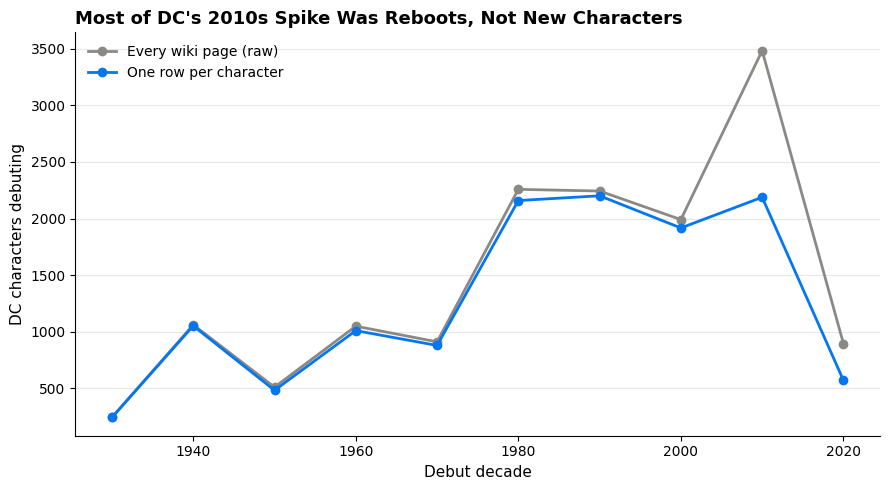

In [ ]:
before = dc_all["debut_decade"].value_counts().sort_index()
after = dc_clean["debut_decade"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(before.index.astype(int), before.values, marker="o", linewidth=2, color="#8a8985", label="Every wiki page (raw)")
ax.plot(after.index.astype(int), after.values, marker="o", linewidth=2, color=PUB_COLORS["DC"], label="One row per character")
finish_chart(ax, "Most of DC's 2010s Spike Was Reboots, Not New Characters",
             "Debut decade", "DC characters debuting", legend_title="")

# Conclusion and Recommendations

### 1. Comics move with America, with a rough delay.

As more American women started working, the share of new female characters in comics rose too. The two match best when comics are compared with the workforce of about 7 years earlier, and this is true for both Marvel and DC. Comics did not lead this change, but our data cannot prove that they reacted to it either.

**Recommendation:** benchmark the gender mix of new characters against current workforce data every year.


### 2. New characters are far more balanced than the roster.

Both rosters are still about 70% male, because most characters were created decades ago. New characters tell a different story: women went from about 1 in 10 new characters in 1960 to 4 in 10 in 2025.

**Recommendation:** keep this direction for new characters, and use legacy characters (successors, team-ups) to rebalance the existing roster.


### 3. Women get “women’s jobs”, and male jobs open up decades late.

Female characters are mostly given jobs where real women were already common, and this has been true in every decade. Comics give women fewer of the jobs that were historically male: female characters reached 1 in 5 of these jobs in the 2010s, while real women did in the 1980s. Management shows the gap most clearly, because it’s where real women made their biggest gains and comics moved the least.

**Recommendation:** cast new female characters across a wider range of roles, especially managerial, professional and other historically male jobs.


### 4. Fewer working lives for everyone.

Female characters are less likely than male characters to have a job at all (57% vs 67%). For new characters this gap has closed, but only because fewer new male characters have a job, not because more women do.

**Recommendation:** give every new character a civilian occupation, so characters read as people with working lives.


### Risks and limitations
- The data has far more male than female characters (35,086 vs 12,334), so female results rest on smaller groups.
- Only 10,832 male and female characters hold a census-type job, so the job comparisons cover about a fifth of the roster.
- Job groups are broad: a "Professional" can be a scientist or an actor, and the "male-dominated" label is fixed in 1940.
- Wiki data is written by volunteers: 5.2% of Marvel characters have no gender, and a missing occupation may just mean an incomplete page.
- 88.9% of characters debuted in 1960 or later, so the earliest decades rest on few characters.
- Correlation over time does not prove that the workforce caused the change in comics; both may follow the same cultural shift.

### Next steps
- Compare the powers given to male and female characters (for example physical vs mental) and how that changed over time.
- Weight characters by importance (number of appearances), so minor characters count less than leads.
- Add race and ethnicity, using census data on the same jobs, to test whether comics mirror America beyond gender.

# References

**Data**
1. Marvel Database (Fandom wiki), Earth-616 characters. https://marvel.fandom.com/wiki/Category:Earth-616/Characters (scraped 29 Sep 2026, CC BY-SA 3.0)
2. DC Database (Fandom wiki). https://dc.fandom.com/wiki/DC_Comics_Database (scraped 29 Sep 2026, CC BY-SA 3.0)
3. Ruggles, S., et al. IPUMS USA. Minneapolis, MN: IPUMS, University of Minnesota. https://usa.ipums.org/usa/
4. U.S. Bureau of Labor Statistics, Labor Force Participation Rate: Women [LNS11300002], retrieved from FRED, Federal Reserve Bank of St. Louis. https://fred.stlouisfed.org/series/LNS11300002

**Software**
5. pandas: https://pandas.pydata.org
6. NumPy: https://numpy.org
7. Matplotlib: https://matplotlib.org
8. seaborn: https://seaborn.pydata.org

# Generative AI Disclosure

In completing this project, we used Generative AI tools to assist with parts of our work. Below is how each team member used them and for which parts of the notebook:

**Emanuele Borroni:**
Code generation: used Claude to help me with the code for the Q7 and Q16 charts.
Writing and editing: used Claude to draft and edit the Executive Summary and the Conclusions, including the recommendations. Also asked Claude to assist me drafting the outlines for the Answer, Interpretation and Caveat for Q7, Q15 and Q16 from the printed outputs, and to check the notebook against the rubric and the instructor’s feedback.

**Albert Dorofeev:**
Code generation: used Claude as a tutor for the Q2, Q4, Q8, Q10 and Q14 charts, asking it to explain how to build each chart step by step instead of giving the finished code. Used Claude to review the Team Assignment cleaning code and refactor it: combining the Marvel and DC cleaning into one shared function, removing repeated imports and merging the code into fewer cells. Writing and editing: used Claude to restructure the notebook into themed sections, align the chart design (colors, titles, labels) and fix typos, and check the notebook against the project rubric and the numbers in the text against the outputs.

**Daniel Igbokwe:**
Code generation: Used Claude to help clean messy Marvel and DC columns, such as gender and occupation. I also brainstormed with Claude to decide how to group the original values into the buckets we specified.
Writing and editing: Used Claude to reformat my rough code so it reads more clearly and is easier to understand.

**Carly Barry:**
Code generation: used ChatGPT for occasional syntax clarification and suggestions for improving code and formatting for Q10 and Q12.
Writing and editing: used ChatGPT to check clarity of my analyses, formatting, and ensure explanations were concise. Used ChatGPT to help improve the organization and consistency of variable descriptions for Data Dictionary.

**Eliza Bashirian:**
Code generation: used Claude Opus 5 to help write the code for the Q4, Q8 and Q14 charts, asking it to go over the code step by step with explanations and to keep to the pandas methods covered in class. Also used Claude to debug errors in my cells, including a variable that was being overwritten by another section of the notebook. Claude helped me review each answered question at the end, so that every graph matches the required question and so on.
Writing and editing: used Claude to draft the Answer, Interpretation and Caveat sections for Q4, Q8 and Q14 from the printed outputs, which I then rewrote in my own words, and to draft the two sentences reporting my Q8 result in the Executive Summary and the Conclusion. Claude also helped the team shape the final list of research questions around our own ideas and the conclusion we were working towards.

Our team has reviewed, run and checked all AI-generated code and text against our own data and notebook outputs to make sure it is accurate, in line with academic integrity guidelines.